# NBFC Loan Default Prediction & Credit Risk Modeling
### From borrower data to a reproducible origination risk model

NBFC credit-risk teams need to identify borrowers with higher probability of loan default to understand portfolio risk and inform lending and monitoring decisions. This notebook estimates **probability of default**: `default = 0` means Non-Defaulter and `default = 1` means Defaulter.

**Scope:** a portfolio/educational project, not a production lending decision engine. The primary model excludes IDs and repayment information. It addresses an origination-stage assessment after loan terms, bank grade and income verification are available; their application-stage timestamps remain an explicit assumption.

**Deliverables:** executed analysis, honest holdout metrics, portable feature transformations, refitted model bundle, deployment configuration, plots and test predictions. An optional existing-loan monitoring comparison remains separate.

**Reading guide:** data and audit → availability review → focused EDA → feature engineering → development experiments → frozen holdout evaluation → explanation and risk bands → refit, export and reload checks.

### Reproducibility
Run from the project root (or `notebooks/`). Install `requirements.txt` in a Python 3.12 environment and select that kernel. Inputs are `Train.csv`, `Test.csv` and `Data_Dictionary.csv` (the supplied `Data_Dictionary_.csv` alias is supported), in the root or `data/`. All modeling uses labeled training data; the supplied test data is only scored at the end. No code edits or absolute machine paths are needed.

## Executive brief — actual executed results

The frozen development choice is **CatBoost**, with **no additional calibration** and threshold **0.28**. On the untouched 20% holdout, **ROC-AUC = 0.8440**, **average precision = 0.6751**, **recall = 0.7004**, **F1 = 0.6162**, and **Brier = 0.12289**. Full comparisons, calibration checks and threshold tradeoffs are below.

**93,174** training loans and **39,933** test loans were processed. The selected model was refitted on all labeled data, exported and reloaded, and every supplied test ID has a binary prediction. The authoritative deployment file is `models/origination_model_bundle.pkl`; use `predict.py` for probability mapping and risk bands.

**Material evidence limitation:** observed default rates decline sharply across ID deciles, and loan-grade ordering is counterintuitive. This flags possible chronology, maturity or construction effects. ID and repayment variables are excluded, but random-split performance cannot establish prospective lending validity. Origination snapshots, horizon and dataset provenance are unverified. This is an educational portfolio model.

## 1. Setup and methods
A fixed seed and bounded CPU settings make experiments reproducible. Warnings remain visible; no blanket suppression is used.

In [1]:
from pathlib import Path
import json
import hashlib
import platform
import importlib.metadata
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, brier_score_loss)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.base import clone
from catboost import CatBoostClassifier, Pool
import shap
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
TARGET, ID_COLUMN = 'default', 'ID'
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'figure.facecolor': 'white',
    'axes.prop_cycle': plt.cycler(color=['#245B82', '#CF8733', '#66784A', '#A75681'])})
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 30)

def locate_project():
    """Locate root without assuming a machine-specific working directory."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if any((candidate / folder / 'Train.csv').exists() for folder in ['', 'data']):
            return candidate
    raise FileNotFoundError('Run from the project root or a child directory containing the CSV inputs.')

ROOT = locate_project()
def find_input(*names):
    for folder in [ROOT, ROOT / 'data']:
        for name in names:
            if (folder / name).exists():
                return folder / name
    raise FileNotFoundError(f'Cannot find any of {names} in root or data/.')

MODELS = ROOT / 'models'
PLOTS = ROOT / 'artifacts' / 'plots'
METRICS = ROOT / 'artifacts' / 'metrics'
PROCESSED = ROOT / 'data' / 'processed'
for folder in [MODELS, PLOTS, METRICS, PROCESSED]:
    folder.mkdir(parents=True, exist_ok=True)

def save_plot(name):
    """Save the current figure for GitHub/README and keep it inline."""
    plt.gcf().savefig(PLOTS / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close()

def write_json(path, value):
    path.write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')

versions = {name: importlib.metadata.version(name) for name in
    ['numpy', 'pandas', 'scikit-learn', 'catboost', 'shap', 'matplotlib', 'joblib', 'nbformat']}
display(pd.Series(versions, name='version').to_frame())

C:\Users\joshi\OneDrive\Desktop\NBFC_Loan\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,version
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
catboost,1.2.10
shap,0.52.0
matplotlib,3.11.2
joblib,1.6.0
nbformat,5.11.1


### Validation design and key assumptions
Reserve **20% untouched stratified holdout**. Split the remaining 80% into fitting (60% of all rows), model/threshold tuning (10%) and calibration (10%). Split calibration again into fitting/check subsets (5% each). Early stopping and model selection use tuning only. Calibration choice uses the calibration check only. Freeze the threshold and risk boundaries before accessing holdout outcomes.

Final performance is a one-time holdout estimate, not a business guarantee. There are no observation timestamps, default horizon, maturity labels or borrower linkage keys; therefore time validation, censoring checks and repeat-borrower isolation cannot be established. The dictionary uses dollars and US state codes: despite the NBFC framing, local currency, country and source provenance are unverified. Bank-assigned rates/grades are assumed available at the assessment stage. Credit balances and histories must refer to a pre-origination snapshot; the dictionary alone cannot establish timestamps. No protected-attribute/fairness, legal or production readiness claim is made.

## 2. Load and understand the source data

,dataset,rows,columns
0,Train,93174,23
1,Test,39933,22


,ID,loan_amnt,loan_term,interest_rate,loan_grade,loan_subgrade,job_experience,home_ownership,annual_income,income_verification_status,loan_purpose,state_code,debt_to_income,delinq_2yrs,public_records,revolving_balance,total_acc,interest_receive,application_type,last_week_pay,total_current_balance,total_revolving_limit,default
0,72199369,9000,3 years,9.17,B,B2,<5 Years,OWN,85000.0,Not Verified,debt_consolidation,NC,26.68,0.0,0.0,39519,20.0,59.60,INDIVIDUAL,4.0,95493.0,84100.0,0
1,14257956,18000,3 years,13.65,C,C1,<5 Years,OWN,64000.0,Verified,debt_consolidation,SC,31.67,0.0,1.0,9783,24.0,3348.25,INDIVIDUAL,95.0,185433.0,13500.0,0
2,66216451,16000,3 years,7.26,A,A4,<5 Years,MORTGAGE,150000.0,Source Verified,debt_consolidation,TX,19.70,2.0,0.0,13641,27.0,276.69,INDIVIDUAL,13.0,180519.0,19300.0,0
3,46974169,25000,3 years,13.99,C,C4,NaN,MORTGAGE,59800.0,Verified,debt_consolidation,MO,37.39,0.0,0.0,35020,35.0,1106.72,INDIVIDUAL,17.0,183208.0,55400.0,0
4,46725961,17000,3 years,6.39,A,A2,10+ years,MORTGAGE,72000.0,Source Verified,credit_card,TX,8.92,0.0,0.0,23990,26.0,725.29,INDIVIDUAL,39.0,23990.0,81300.0,0


,ID,loan_amnt,loan_term,interest_rate,loan_grade,loan_subgrade,job_experience,home_ownership,annual_income,income_verification_status,loan_purpose,state_code,debt_to_income,delinq_2yrs,public_records,revolving_balance,total_acc,interest_receive,application_type,last_week_pay,total_current_balance,total_revolving_limit
0,4855329,12000,3 years,15.31,C,C2,<5 Years,MORTGAGE,73400.0,Not Verified,debt_consolidation,CA,14.62,0.0,0.0,22156,30.0,2290.24,INDIVIDUAL,87.0,128098.0,25800.0
1,66862420,12000,3 years,7.26,A,A4,10+ years,MORTGAGE,105000.0,Not Verified,credit_card,VA,11.38,0.0,0.0,7592,14.0,202.68,INDIVIDUAL,13.0,269396.0,23600.0
2,3637416,15000,3 years,14.33,C,C1,6-10 years,MORTGAGE,50000.0,Verified,debt_consolidation,TX,28.15,0.0,1.0,17983,19.0,1166.24,INDIVIDUAL,30.0,220135.0,34100.0
3,53682249,12000,3 years,9.99,B,B3,6-10 years,RENT,37000.0,Source Verified,credit_card,NJ,34.32,0.0,0.0,12262,18.0,635.06,INDIVIDUAL,35.0,39436.0,21700.0
4,53937165,20150,3 years,11.53,B,B5,<5 Years,RENT,75000.0,Source Verified,debt_consolidation,CA,26.74,1.0,0.0,8251,11.0,1232.84,INDIVIDUAL,31.0,52764.0,12000.0


,feature,business_meaning
0,ID,unique ID assigned to each applicant
1,loan_amnt,loan amount ($) applied each applicant
2,loan_term,Loan duration in years
3,interest_rate,Applicable interest rate on Loan in %
4,loan_grade,Loan Grade Assigned by the bank
5,loan_subgrade,Loan SubGrade Assigned by the bank
6,job_experience,Number of years job experience
7,home_ownership,Status of House Ownership
8,annual_income,Annual income of the applicant
9,income_verification_status,Status of Income verification by the bank


Training columns: ['ID', 'loan_amnt', 'loan_term', 'interest_rate', 'loan_grade', 'loan_subgrade', 'job_experience', 'home_ownership', 'annual_income', 'income_verification_status', 'loan_purpose', 'state_code', 'debt_to_income', 'delinq_2yrs', 'public_records', 'revolving_balance', 'total_acc', 'interest_receive', 'application_type', 'last_week_pay', 'total_current_balance', 'total_revolving_limit', 'default']
Test columns: ['ID', 'loan_amnt', 'loan_term', 'interest_rate', 'loan_grade', 'loan_subgrade', 'job_experience', 'home_ownership', 'annual_income', 'income_verification_status', 'loan_purpose', 'state_code', 'debt_to_income', 'delinq_2yrs', 'public_records', 'revolving_balance', 'total_acc', 'interest_receive', 'application_type', 'last_week_pay', 'total_current_balance', 'total_revolving_limit']
<class 'pandas.DataFrame'>
RangeIndex: 93174 entries, 0 to 93173
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                   

,ID,loan_amnt,interest_rate,annual_income,debt_to_income,delinq_2yrs,public_records,revolving_balance,total_acc,interest_receive,last_week_pay,total_current_balance,total_revolving_limit,default
count,93174.00,93174.00,93174.00,93173.00,93174.00,93172.00,93172.00,93174.00,93172.00,93174.00,91250.00,85788.00,85788.00,93174.00
mean,35050211.39,14733.86,13.23,75028.26,18.13,0.32,0.20,16854.47,25.25,1747.26,58.15,139252.92,32085.90,0.24
std,24149262.07,8428.18,4.37,69454.78,8.56,0.88,0.58,23689.07,11.86,2088.24,44.33,157686.79,47052.51,0.43
min,70735.00,500.00,5.32,1200.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
25%,10859832.50,8000.00,9.99,45000.00,11.93,0.00,0.00,6433.00,17.00,439.88,22.00,29642.00,14000.00,0.00
50%,37107507.00,13000.00,12.99,64000.00,17.64,0.00,0.00,11856.00,24.00,1070.76,48.00,79363.50,23700.00,0.00
75%,58598949.50,20000.00,16.20,90000.00,23.89,0.00,0.00,20745.00,32.00,2219.61,83.00,207160.00,39700.00,0.00
max,73519746.00,35000.00,28.99,9500000.00,672.52,22.00,49.00,2560703.00,119.00,23172.31,291.00,8000078.00,9999999.00,1.00


Numeric: ['ID', 'loan_amnt', 'interest_rate', 'annual_income', 'debt_to_income', 'delinq_2yrs', 'public_records', 'revolving_balance', 'total_acc', 'interest_receive', 'last_week_pay', 'total_current_balance', 'total_revolving_limit', 'default']
Categorical: ['application_type', 'home_ownership', 'income_verification_status', 'job_experience', 'loan_grade', 'loan_purpose', 'loan_subgrade', 'loan_term', 'state_code']


,unique_including_missing
ID,93174
loan_amnt,1310
loan_term,2
interest_rate,481
loan_grade,7
loan_subgrade,35
job_experience,4
home_ownership,5
annual_income,8668
income_verification_status,3


,count,percentage
default,,
0,71045,76.249812
1,22129,23.750188


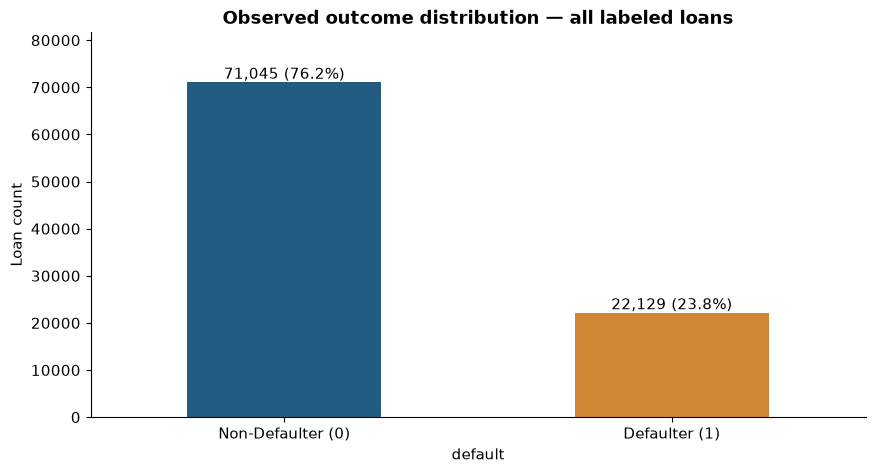

**Observed default rate: 23.75%.** Accuracy alone can reward a model that misses defaults; ROC-AUC, average precision, recall, F1 and probability reliability will also be evaluated.

In [2]:
input_paths = {'train': find_input('Train.csv'), 'test': find_input('Test.csv'),
    'dictionary': find_input('Data_Dictionary.csv', 'Data_Dictionary_.csv')}
train_df = pd.read_csv(input_paths['train'])
test_df = pd.read_csv(input_paths['test'])
data_dictionary = pd.read_csv(input_paths['dictionary'], header=None,
    names=['feature', 'business_meaning'])
assert train_df[TARGET].notna().all() and set(train_df[TARGET].unique()) == {0, 1}
assert TARGET not in test_df
display(pd.DataFrame({'dataset': ['Train', 'Test'],
    'rows': [len(train_df), len(test_df)], 'columns': [train_df.shape[1], test_df.shape[1]]}))
display(train_df.head(), test_df.head())
display(data_dictionary)
print('Training columns:', train_df.columns.tolist())
print('Test columns:', test_df.columns.tolist())
train_df.info()
display(train_df.describe().round(2))
numeric_columns = train_df.select_dtypes(include='number').columns.tolist()
categorical_columns = train_df.columns.difference(numeric_columns).tolist()
print('Numeric:', numeric_columns)
print('Categorical:', categorical_columns)
display(train_df.nunique(dropna=False).rename('unique_including_missing').to_frame())
default_rate = float(train_df[TARGET].mean())
class_distribution = train_df[TARGET].value_counts().sort_index().to_frame('count')
class_distribution['percentage'] = class_distribution['count'] / len(train_df) * 100
display(class_distribution)
ax = class_distribution['count'].plot.bar(color=['#245B82', '#CF8733'], rot=0)
ax.set(xticklabels=['Non-Defaulter (0)', 'Defaulter (1)'], ylabel='Loan count',
    title='Observed outcome distribution — all labeled loans')
for i, row in enumerate(class_distribution.itertuples()):
    ax.text(i, row.count, f'{row.count:,} ({row.percentage:.1f}%)', ha='center', va='bottom')
ax.set_ylim(0, class_distribution['count'].max() * 1.15)
save_plot('target_distribution.png')
display(Markdown(f'**Observed default rate: {default_rate:.2%}.** Accuracy alone can reward a model that misses defaults; ROC-AUC, average precision, recall, F1 and probability reliability will also be evaluated.'))

## 3. Reusable data-quality audit
Audit findings guide treatment; no rows are removed automatically. Missingness is retained for CatBoost or imputed inside the sklearn pipeline. Train/test audits inspect covariates only and never guide supervised selection.

In [3]:
def quality_summary(df):
    """One row per source column with reproducible missingness/cardinality checks."""
    return pd.DataFrame([{'column': c, 'dtype': str(df[c].dtype),
        'missing_count': int(df[c].isna().sum()), 'missing_pct': float(df[c].isna().mean() * 100),
        'unique_values': int(df[c].nunique()),
        'sample_values': str(df[c].dropna().unique()[:4].tolist()),
        'largest_value_share': float(df[c].value_counts(dropna=False, normalize=True).max())}
        for c in df])

train_quality, test_quality = quality_summary(train_df), quality_summary(test_df)
display(train_quality)
train_quality.to_csv(METRICS / 'train_data_quality.csv', index=False)
test_quality.to_csv(METRICS / 'test_data_quality.csv', index=False)
schema_diff = {'train_only': sorted(set(train_df) - set(test_df)),
    'test_only': sorted(set(test_df) - set(train_df)),
    'dtype_differences': [c for c in test_df if c in train_df and train_df[c].dtype != test_df[c].dtype]}
assert schema_diff['train_only'] == [TARGET] and not schema_diff['test_only']
audit = {'train_duplicate_rows': int(train_df.duplicated().sum()),
    'test_duplicate_rows': int(test_df.duplicated().sum()),
    'train_duplicate_ids': int(train_df[ID_COLUMN].duplicated().sum()),
    'test_duplicate_ids': int(test_df[ID_COLUMN].duplicated().sum()),
    'train_test_id_overlap': len(set(train_df[ID_COLUMN]) & set(test_df[ID_COLUMN])),
    'train_missing_ids': int(train_df[ID_COLUMN].isna().sum()),
    'test_missing_ids': int(test_df[ID_COLUMN].isna().sum()),
    'constant_columns': train_quality.loc[train_quality.unique_values <= 1, 'column'].tolist(),
    'near_constant_columns_99pct': train_quality.loc[train_quality.largest_value_share >= .99, 'column'].tolist(),
    'schema': schema_diff}
display(pd.Series(audit, name='finding').to_frame())
category_differences = pd.DataFrame([{'column': c,
    'train_only': sorted(set(train_df[c].dropna()) - set(test_df[c].dropna())),
    'test_only': sorted(set(test_df[c].dropna()) - set(train_df[c].dropna()))}
    for c in categorical_columns])
display(category_differences)
category_differences.to_csv(METRICS / 'category_differences.csv', index=False)

def numeric_validity(df):
    rows = []
    for c in df.select_dtypes(include='number'):
        if c in [ID_COLUMN, TARGET]:
            continue
        series = df[c]
        rows.append({'column': c, 'negative': int((series < 0).sum()),
            'zero': int((series == 0).sum()), 'infinite': int(np.isinf(series).sum()),
            'min': float(series.min()), 'max': float(series.max())})
    return pd.DataFrame(rows)

display(numeric_validity(train_df))
numeric_validity(train_df).to_csv(METRICS / 'numeric_validity.csv', index=False)
domain_checks = pd.DataFrame([{'dataset': name,
    'nonpositive_loan': int((df.loan_amnt <= 0).sum()),
    'rate_outside_0_100': int(((df.interest_rate < 0) | (df.interest_rate > 100)).sum()),
    'nonpositive_income': int((df.annual_income <= 0).sum()),
    'zero_revolving_limit': int((df.total_revolving_limit == 0).sum()),
    'dti_above_100_review': int((df.debt_to_income > 100).sum()),
    'noninteger_history_counts': int(sum(((df[c].dropna() % 1) != 0).sum()
        for c in ['delinq_2yrs', 'public_records', 'total_acc'])),
    'unexpected_term': int((~df.loan_term.isin(['3 years', '5 years'])).sum()),
    'unexpected_grade': int((~df.loan_grade.isin(list('ABCDEFG'))).sum()),
    'invalid_subgrade': int((~df.loan_subgrade.astype('string').str.match(r'^[A-G][1-5]$')).sum())}
    for name, df in [('Train', train_df), ('Test', test_df)]])
display(domain_checks)
domain_checks.to_csv(METRICS / 'domain_checks.csv', index=False)
write_json(METRICS / 'audit_summary.json', audit)
largest_missing = train_quality.sort_values('missing_pct', ascending=False).iloc[0]
display(Markdown(f'The most incomplete training field is **{largest_missing.column} ({largest_missing.missing_pct:.2f}%)**. Missing job experience is a distinct unknown category. Zero revolving limits create undefined utilization ratios and will produce NaN, not infinity. DTI above 100 and extreme balances are review flags rather than proven errors: units and source records are unavailable. Near-constant application type is retained, but rare joint applicants limit subgroup conclusions. No blanket deletion, winsorization or oversampling is applied.'))

,column,dtype,missing_count,missing_pct,unique_values,sample_values,largest_value_share
0,ID,int64,0,0.000000,93174,"[72199369, 14257956, 66216451, 46974169]",0.000011
1,loan_amnt,int64,0,0.000000,1310,"[9000, 18000, 16000, 25000]",0.070052
2,loan_term,str,0,0.000000,2,"['3 years', '5 years']",0.699884
3,interest_rate,float64,0,0.000000,481,"[9.17, 13.65, 7.26, 13.99]",0.038734
4,loan_grade,str,0,0.000000,7,"['B', 'C', 'A', 'E']",0.288332
5,loan_subgrade,str,0,0.000000,35,"['B2', 'C1', 'A4', 'C4']",0.063097
6,job_experience,str,4702,5.046472,3,"['<5 Years', '10+ years', '6-10 years']",0.435851
7,home_ownership,str,0,0.000000,5,"['OWN', 'MORTGAGE', 'RENT', 'NONE']",0.498476
8,annual_income,float64,1,0.001073,8667,"[85000.0, 64000.0, 150000.0, 59800.0]",0.039110
9,income_verification_status,str,0,0.000000,3,"['Not Verified', 'Verified', 'Source Verified']",0.370135


,finding
train_duplicate_rows,0
test_duplicate_rows,0
train_duplicate_ids,0
test_duplicate_ids,0
train_test_id_overlap,0
train_missing_ids,0
test_missing_ids,0
constant_columns,[]
near_constant_columns_99pct,[application_type]
schema,"{'train_only': ['default'], 'test_only': [], '..."


,column,train_only,test_only
0,application_type,[],[]
1,home_ownership,[],[]
2,income_verification_status,[],[]
3,job_experience,[],[]
4,loan_grade,[],[]
5,loan_purpose,[],[]
6,loan_subgrade,[],[]
7,loan_term,[],[]
8,state_code,[],[]


,column,negative,zero,infinite,min,max
0,loan_amnt,0,0,0,500.00,35000.00
1,interest_rate,0,0,0,5.32,28.99
2,annual_income,0,0,0,1200.00,9500000.00
3,debt_to_income,0,40,0,0.00,672.52
4,delinq_2yrs,0,75315,0,0.00,22.00
5,public_records,0,78934,0,0.00,49.00
6,revolving_balance,0,340,0,0.00,2560703.00
7,total_acc,0,0,0,1.00,119.00
8,interest_receive,0,1984,0,0.00,23172.31
9,last_week_pay,0,127,0,0.00,291.00


,dataset,nonpositive_loan,rate_outside_0_100,nonpositive_income,zero_revolving_limit,dti_above_100_review,noninteger_history_counts,unexpected_term,unexpected_grade,invalid_subgrade
0,Train,0,0,0,34,1,0,0,0,0
1,Test,0,0,0,16,1,0,0,0,0


The most incomplete training field is **total_current_balance (7.93%)**. Missing job experience is a distinct unknown category. Zero revolving limits create undefined utilization ratios and will produce NaN, not infinity. DTI above 100 and extreme balances are review flags rather than proven errors: units and source records are unavailable. Near-constant application type is retained, but rare joint applicants limit subgroup conclusions. No blanket deletion, winsorization or oversampling is applied.

## 4. Availability and leakage review
**Loan Origination Model (primary):** use borrower/application information and pre-loan credit snapshots. The dictionary defines `interest_receive` as interest received by the bank on the loan and `last_week_pay` as months of EMI already paid, despite its name. Both are post-origination and excluded. `ID` identifies applicants and is excluded even if predictive.

**Existing Loan Early Warning Model (secondary):** repayment fields can be considered only for already active loans with a specified observation date and future outcome window. The optional comparison here is illustrative: those timing fields are absent, so it cannot establish deployable early-warning validity.

Availability is assessed for every variable below; neither strong association nor a dictionary label proves correct timestamps.

In [4]:
post_loan = ['interest_receive', 'last_week_pay']
conditional_pricing = ['interest_rate', 'loan_grade', 'loan_subgrade', 'income_verification_status']
snapshot_fields = ['debt_to_income', 'delinq_2yrs', 'public_records', 'revolving_balance',
    'total_acc', 'total_current_balance', 'total_revolving_limit']
availability = data_dictionary.copy()
def availability_decision(c):
    if c == TARGET:
        return 'Outcome only — exclude'
    if c == ID_COLUMN:
        return 'Identifier — exclude'
    if c in post_loan:
        return 'Post-loan repayment — exclude from origination'
    if c in conditional_pricing:
        return 'Conditional: available after pricing/grading/verification; retain for specified assessment stage'
    if c in snapshot_fields:
        return 'Conditional: retain only as a pre-origination credit snapshot; timestamps unverified'
    return 'Application information — provisionally available at assessment'
availability['availability_decision'] = availability.feature.map(availability_decision)
display(availability)
availability.to_csv(METRICS / 'feature_availability_review.csv', index=False)

,feature,business_meaning,availability_decision
0,ID,unique ID assigned to each applicant,Identifier — exclude
1,loan_amnt,loan amount ($) applied each applicant,Application information — provisionally availa...
2,loan_term,Loan duration in years,Application information — provisionally availa...
3,interest_rate,Applicable interest rate on Loan in %,Conditional: available after pricing/grading/v...
4,loan_grade,Loan Grade Assigned by the bank,Conditional: available after pricing/grading/v...
5,loan_subgrade,Loan SubGrade Assigned by the bank,Conditional: available after pricing/grading/v...
6,job_experience,Number of years job experience,Application information — provisionally availa...
7,home_ownership,Status of House Ownership,Application information — provisionally availa...
8,annual_income,Annual income of the applicant,Application information — provisionally availa...
9,income_verification_status,Status of Income verification by the bank,Conditional: available after pricing/grading/v...


## 5. Shared feature engineering
Four affordability/exposure ratios use positive denominators. Values above 1 are preserved. Loan duration becomes years. Job categories are normalized for case/whitespace without inventing exact years from broad ranges. Grade and subgrade stay categorical: ordinal duplicates would add redundancy; CatBoost can learn their ordering associations. The same deterministic functions serve validation, test and deployment.

In [5]:
"""Portable, deterministic origination transformations shared by notebook and app."""
import numpy as np
import pandas as pd

EXCLUDED_FEATURES = ['ID', 'default', 'interest_receive', 'last_week_pay']
CATEGORICAL_FEATURES = ['loan_grade', 'loan_subgrade', 'job_experience',
    'home_ownership', 'income_verification_status', 'loan_purpose',
    'state_code', 'application_type']
EXPECTED_INPUT_COLUMNS = ['loan_amnt', 'loan_term', 'interest_rate', 'loan_grade',
    'loan_subgrade', 'job_experience', 'home_ownership', 'annual_income',
    'income_verification_status', 'loan_purpose', 'state_code', 'debt_to_income',
    'delinq_2yrs', 'public_records', 'revolving_balance', 'total_acc',
    'application_type', 'total_current_balance', 'total_revolving_limit']
FEATURE_DEFINITIONS = {
    'loan_term_years': 'Leading numeric duration from loan_term, in years; replaces original.',
    'loan_to_income': 'loan_amnt / annual_income when denominator > 0; otherwise NaN.',
    'credit_utilization': 'revolving_balance / total_revolving_limit when denominator > 0; otherwise NaN; not capped.',
    'balance_to_income': 'total_current_balance / annual_income when denominator > 0; otherwise NaN.',
    'revolving_to_income': 'revolving_balance / annual_income when denominator > 0; otherwise NaN.'
}

def create_features(df):
    """Accept raw borrower rows; exclude outcome/IDs/repayment fields explicitly."""
    missing = sorted(set(EXPECTED_INPUT_COLUMNS) - set(df.columns))
    if missing:
        raise ValueError(f'Missing expected borrower fields: {missing}')
    result = df[EXPECTED_INPUT_COLUMNS].copy()
    result['loan_term_years'] = pd.to_numeric(
        result.pop('loan_term').astype('string').str.extract(r'^(\d+(?:\.\d+)?)', expand=False),
        errors='coerce').astype(float)
    for column in CATEGORICAL_FEATURES:
        result[column] = result[column].astype('string').str.strip().fillna('__MISSING__').astype(object)
    result['job_experience'] = result['job_experience'].str.lower()
    for column in result.columns.difference(CATEGORICAL_FEATURES):
        result[column] = pd.to_numeric(result[column], errors='coerce').astype(float)
    for feature, numerator, denominator in [
        ('loan_to_income', 'loan_amnt', 'annual_income'),
        ('credit_utilization', 'revolving_balance', 'total_revolving_limit'),
        ('balance_to_income', 'total_current_balance', 'annual_income'),
        ('revolving_to_income', 'revolving_balance', 'annual_income')]:
        result[feature] = result[numerator].div(result[denominator].where(result[denominator] > 0))
    numerical = result.columns.difference(CATEGORICAL_FEATURES)
    result[numerical] = result[numerical].replace([np.inf, -np.inf], np.nan)
    return result

def probability_input(probabilities):
    """Log odds for a sigmoid calibration model, avoiding infinities."""
    p = np.clip(np.asarray(probabilities, dtype=float), 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p)).reshape(-1, 1)

def calibrated_probability(model, features, calibrator=None, method='none'):
    """Return default probabilities, with the saved optional mapping."""
    p = model.predict_proba(features)[:, 1]
    if method == 'sigmoid':
        p = calibrator.predict_proba(probability_input(p))[:, 1]
    elif method == 'isotonic':
        p = calibrator.predict(p)
    return np.asarray(p)

def assign_risk_band(probability, boundaries):
    """Use left-closed risk bands; a boundary value enters the higher band."""
    return ['Low', 'Moderate', 'High', 'Very High'][
        int(np.searchsorted(boundaries, probability, side='right'))]

In [6]:
X = create_features(train_df)
y = train_df[TARGET].astype(int)
test_features = create_features(test_df)
FEATURE_COLUMNS = X.columns.tolist()
NUMERICAL_FEATURES = X.columns.difference(CATEGORICAL_FEATURES).tolist()
assert test_features.columns.tolist() == FEATURE_COLUMNS
assert not set(EXCLUDED_FEATURES) & set(FEATURE_COLUMNS)
assert not np.isinf(X[NUMERICAL_FEATURES].to_numpy()).any()
display(pd.DataFrame({'feature': FEATURE_COLUMNS,
    'type': ['categorical' if c in CATEGORICAL_FEATURES else 'numerical' for c in FEATURE_COLUMNS]}))
ratio_audit = X[list(FEATURE_DEFINITIONS)].describe().T
display(ratio_audit)
display(pd.DataFrame({'ratio': list(FEATURE_DEFINITIONS),
    'definition': list(FEATURE_DEFINITIONS.values())}))
X.to_csv(PROCESSED / 'train_features.csv', index=False)
test_features.to_csv(PROCESSED / 'test_features.csv', index=False)

,feature,type
0,loan_amnt,numerical
1,interest_rate,numerical
2,loan_grade,categorical
3,loan_subgrade,categorical
4,job_experience,categorical
5,home_ownership,categorical
6,annual_income,numerical
7,income_verification_status,categorical
8,loan_purpose,categorical
9,state_code,categorical


,count,mean,std,min,25%,50%,75%,max
loan_term_years,93174.0,3.600232,0.916621,3.000000,3.000000,3.000000,5.000000,5.000000
loan_to_income,93173.0,0.221591,0.116594,0.001185,0.133333,0.208333,0.300000,10.000000
credit_utilization,85754.0,0.554133,0.235085,0.000000,0.381667,0.561156,0.735925,1.507097
balance_to_income,85788.0,1.795185,1.551189,0.000000,0.527718,1.248465,2.806890,19.637500
revolving_to_income,93173.0,0.237384,0.202998,0.000000,0.108303,0.193289,0.312047,5.425040


,ratio,definition
0,loan_term_years,"Leading numeric duration from loan_term, in ye..."
1,loan_to_income,loan_amnt / annual_income when denominator > 0...
2,credit_utilization,revolving_balance / total_revolving_limit when...
3,balance_to_income,total_current_balance / annual_income when den...
4,revolving_to_income,revolving_balance / annual_income when denomin...


## 6. Lock the data partitions
EDA and ID diagnostics below use development rows only. The holdout labels remain untouched until model, calibration, threshold and band definitions are frozen.

In [7]:
development_index, validation_index = train_test_split(train_df.index, test_size=.20,
    stratify=y, random_state=RANDOM_STATE)
fit_index, auxiliary_index = train_test_split(development_index, test_size=.25,
    stratify=y.loc[development_index], random_state=RANDOM_STATE)
tune_index, calibration_index = train_test_split(auxiliary_index, test_size=.50,
    stratify=y.loc[auxiliary_index], random_state=RANDOM_STATE)
cal_fit_index, cal_check_index = train_test_split(calibration_index, test_size=.50,
    stratify=y.loc[calibration_index], random_state=RANDOM_STATE)
X_train, y_train = X.loc[fit_index], y.loc[fit_index]
X_tune, y_tune = X.loc[tune_index], y.loc[tune_index]
X_valid, y_valid = X.loc[validation_index], y.loc[validation_index]
parts = {'fit': fit_index, 'tune': tune_index, 'calibration_fit': cal_fit_index,
    'calibration_check': cal_check_index, 'untouched_holdout': validation_index}
assert len(set().union(*(set(v) for v in parts.values()))) == len(train_df)
assert sum(map(len, parts.values())) == len(train_df)
display(pd.DataFrame([{'partition': k, 'rows': len(v), 'features': len(FEATURE_COLUMNS),
    'default_rate': y.loc[v].mean(), 'defaults': int(y.loc[v].sum())} for k, v in parts.items()]))
split_manifest = pd.DataFrame({'ID': train_df[ID_COLUMN], 'partition': ''})
for name, indices in parts.items():
    split_manifest.loc[indices, 'partition'] = name
split_manifest.to_csv(METRICS / 'split_manifest.csv', index=False)
eda_df = train_df.loc[development_index].copy()

,partition,rows,features,default_rate,defaults
0,fit,55904,23,0.237496,13277
1,tune,9317,23,0.237523,2213
2,calibration_fit,4659,23,0.237605,1107
3,calibration_check,4659,23,0.237390,1106
4,untouched_holdout,18635,23,0.237510,4426


## 7. ID artifact diagnostic
An ID-only shallow model and binned outcome rates test whether identifiers encode ordering, chronology or construction artifacts. This diagnostic uses fitting/tuning data and does not make ID eligible for underwriting.

,count,mean
id_bin,,
"(70734.999, 1988324.2]",7454,0.776362
"(1988324.2, 8320308.2]",7454,0.490609
"(8320308.2, 14398097.4]",7454,0.350148
"(14398097.4, 23393695.2]",7454,0.262678
"(23393695.2, 37156505.0]",7454,0.194795
"(37156505.0, 45261993.8]",7453,0.131625
"(45261993.8, 53895185.6]",7454,0.084787
"(53895185.6, 61466417.0]",7454,0.050174
"(61466417.0, 67678788.4]",7454,0.025490


ID-only tuning ROC-AUC: 0.8363; Pearson correlation: -0.4928


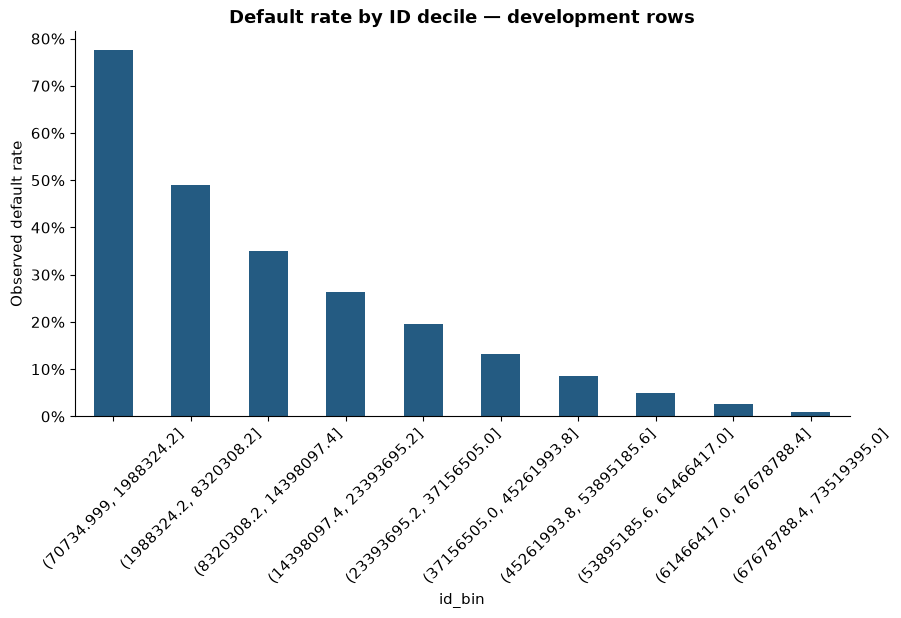

ID-only ROC-AUC is **0.836**. Any predictive signal here is an artifact warning, not a borrower credit characteristic. Random splits may conceal chronology/maturity differences. ID stays excluded; a future time-based audit requires real origination and outcome dates.

In [8]:
id_diagnostic = RandomForestClassifier(n_estimators=80, max_depth=4,
    min_samples_leaf=100, random_state=RANDOM_STATE, n_jobs=4)
id_diagnostic.fit(train_df.loc[fit_index, [ID_COLUMN]], y_train)
id_auc = roc_auc_score(y_tune, id_diagnostic.predict_proba(train_df.loc[tune_index, [ID_COLUMN]])[:, 1])
id_correlation = eda_df[[ID_COLUMN, TARGET]].corr().iloc[0, 1]
id_bins = eda_df.assign(id_bin=pd.qcut(eda_df[ID_COLUMN], 10, duplicates='drop')).groupby(
    'id_bin', observed=True)[TARGET].agg(['count', 'mean'])
display(id_bins)
print(f'ID-only tuning ROC-AUC: {id_auc:.4f}; Pearson correlation: {id_correlation:.4f}')
ax = id_bins['mean'].plot.bar(rot=45)
ax.set(ylabel='Observed default rate', title='Default rate by ID decile — development rows')
ax.yaxis.set_major_formatter(PercentFormatter(1))
save_plot('id_diagnostic.png')
display(Markdown(f'ID-only ROC-AUC is **{id_auc:.3f}**. Any predictive signal here is an artifact warning, not a borrower credit characteristic. Random splits may conceal chronology/maturity differences. ID stays excluded; a future time-based audit requires real origination and outcome dates.'))

## 8. Focused exploratory analysis
All charts in this section use the development subset. Category rates include loan counts and approximate 95% Wilson intervals. Group differences are descriptive associations, with no causal interpretation. Rare categories remain visible. Income/credit distributions are clipped at the 99th percentile for display only; modeling values are unchanged.

In [9]:
def grouped_rates(groups):
    """Counts, default rates and Wilson intervals using development loans."""
    frame = pd.DataFrame({'group': groups, 'default': eda_df[TARGET]})
    result = frame.groupby('group', observed=True, dropna=False)['default'].agg(['count', 'sum', 'mean'])
    n, p, z = result['count'], result['mean'], 1.96
    center = (p + z*z / (2*n)) / (1 + z*z/n)
    half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    result['lower'], result['upper'] = center-half, center+half
    return result

def rate_chart(column, bins=False):
    """Readable category/quantile rates plus computed association commentary."""
    values = eda_df[column]
    groups = pd.qcut(values, 5, duplicates='drop') if bins else values.fillna('Missing').astype(str)
    rates = grouped_rates(groups)
    if not bins:
        rates = rates.sort_index() if column in ['loan_grade', 'loan_subgrade', 'loan_term'] else rates.sort_values('mean')
    height = max(4, len(rates) * .32)
    fig, ax = plt.subplots(figsize=(10, height))
    positions = np.arange(len(rates))
    ax.barh(positions, rates['mean'], color='#245B82')
    ax.errorbar(rates['mean'], positions,
        xerr=[rates['mean']-rates['lower'], rates['upper']-rates['mean']], fmt='none', color='#263238', capsize=2)
    ax.set_yticks(positions, [f'{g} (n={n:,})' for g, n in zip(rates.index, rates['count'])])
    ax.set(xlabel='Observed default rate (95% Wilson interval)', title=f'Default rate by {column.replace("_", " ")} — development')
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.axvline(eda_df[TARGET].mean(), linestyle='--', color='#66784A', label='Development default rate')
    ax.legend(loc='lower right')
    save_plot(f'eda_{column}_rates.png')
    rates.to_csv(METRICS / f'eda_{column}_rates.csv')
    substantial = rates[rates['count'] >= 100]
    if len(substantial):
        highest = substantial['mean'].idxmax()
        lowest = substantial['mean'].idxmin()
        display(Markdown(f'**Observed association:** among groups with at least 100 loans, **{highest}** has a default rate of **{substantial.loc[highest, "mean"]:.1%}** versus **{substantial.loc[lowest, "mean"]:.1%}** for **{lowest}**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.'))
    return rates

def distribution_chart(column, clip=False):
    values = eda_df[column].dropna()
    upper = values.quantile(.99) if clip else values.max()
    shown = values[values <= upper]
    fig, ax = plt.subplots()
    ax.hist(shown, bins=40, color='#245B82', edgecolor='white')
    ax.set(xlabel=column.replace('_', ' '), ylabel='Loan count',
        title=f'{column.replace("_", " ").title()} distribution — development' + (' (≤99th percentile)' if clip else ''))
    save_plot(f'eda_{column}_distribution.png')
    display(Markdown(f'**Distribution:** median {column} is **{values.median():,.2f}**, compared with a 99th percentile of **{values.quantile(.99):,.2f}**. The plot displays **{len(shown):,}** nonmissing observations; {len(values)-len(shown):,} upper-tail values are omitted from this view only. These descriptive values do not justify deleting extreme records.'))

### Loan Amnt
Compare the source distribution with observed default rates by development-set quantiles. Currency fields retain the dictionary’s units.

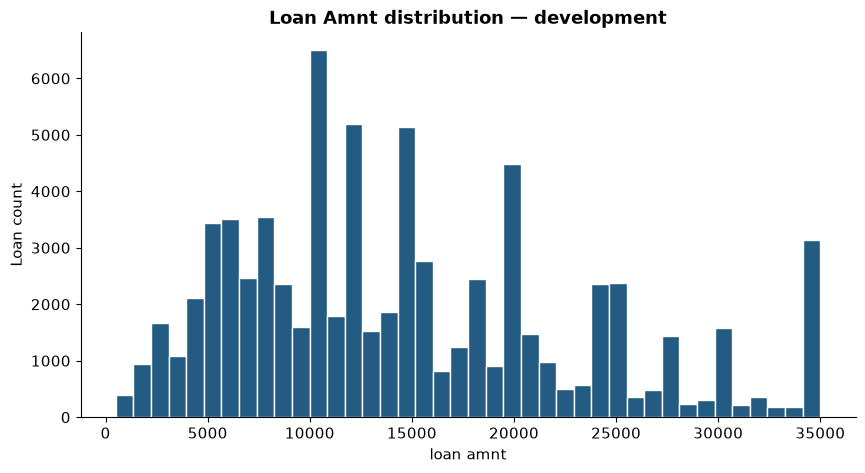

**Distribution:** median loan_amnt is **13,000.00**, compared with a 99th percentile of **35,000.00**. The plot displays **74,539** nonmissing observations; 0 upper-tail values are omitted from this view only. These descriptive values do not justify deleting extreme records.

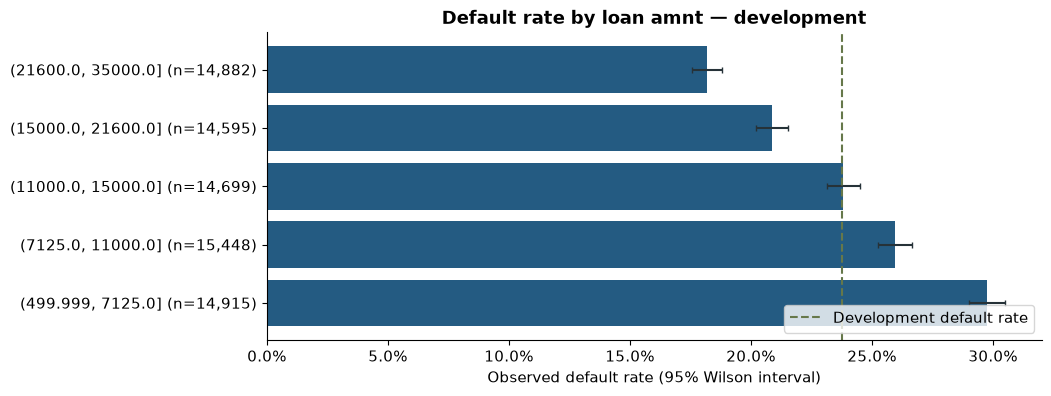

**Observed association:** among groups with at least 100 loans, **(499.999, 7125.0]** has a default rate of **29.8%** versus **18.2%** for **(21600.0, 35000.0]**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.

In [10]:
distribution_chart('loan_amnt', clip=False)
rate_chart('loan_amnt', bins=True);

### Interest Rate
Compare the source distribution with observed default rates by development-set quantiles. Currency fields retain the dictionary’s units.

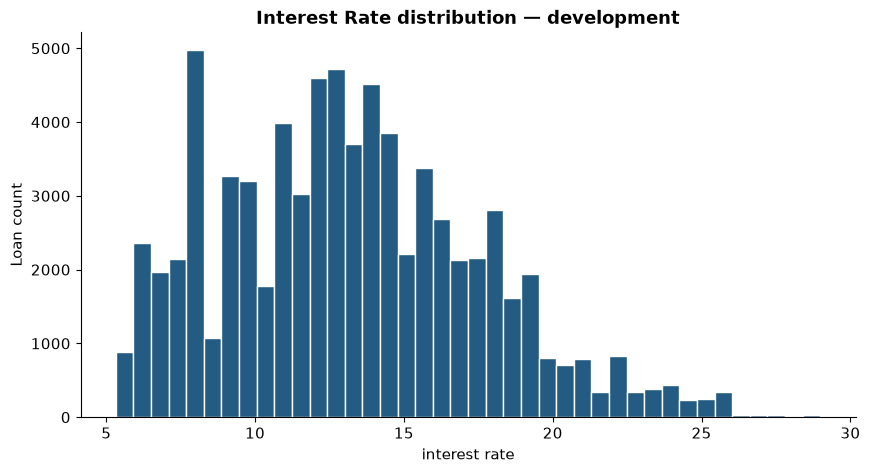

**Distribution:** median interest_rate is **12.99**, compared with a 99th percentile of **24.70**. The plot displays **74,539** nonmissing observations; 0 upper-tail values are omitted from this view only. These descriptive values do not justify deleting extreme records.

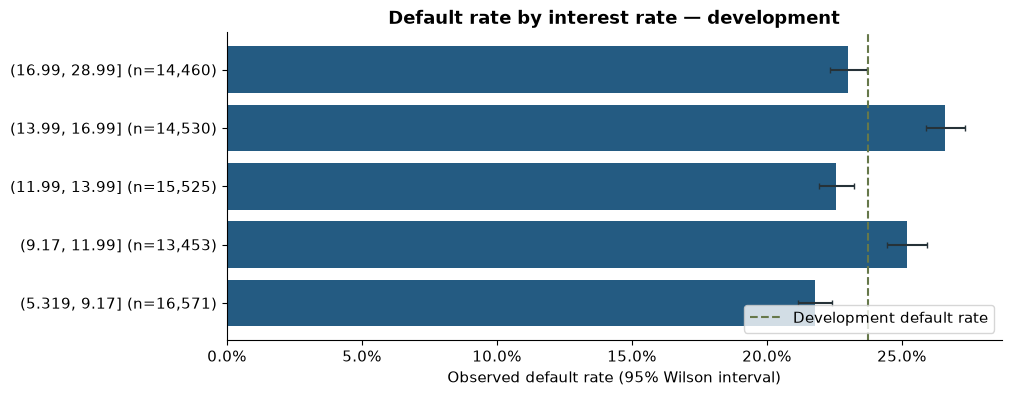

**Observed association:** among groups with at least 100 loans, **(13.99, 16.99]** has a default rate of **26.6%** versus **21.8%** for **(5.319, 9.17]**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.

In [11]:
distribution_chart('interest_rate', clip=False)
rate_chart('interest_rate', bins=True);

### Annual Income
Compare the source distribution with observed default rates by development-set quantiles. Currency fields retain the dictionary’s units.

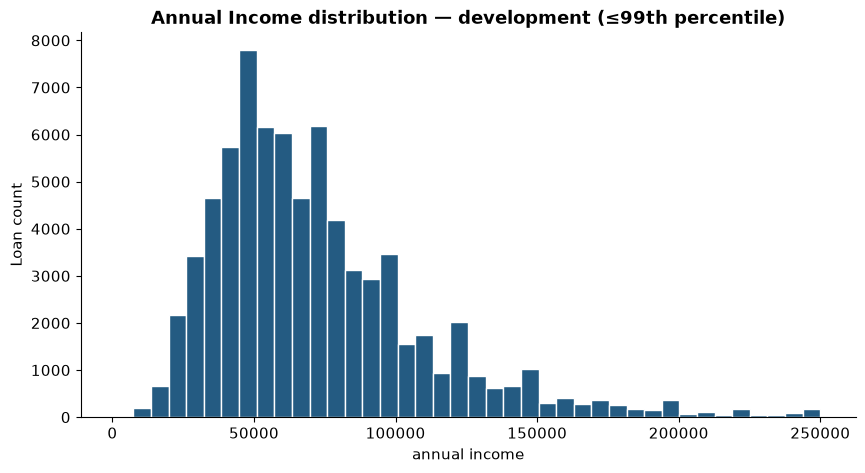

**Distribution:** median annual_income is **64,000.00**, compared with a 99th percentile of **250,000.00**. The plot displays **73,843** nonmissing observations; 695 upper-tail values are omitted from this view only. These descriptive values do not justify deleting extreme records.

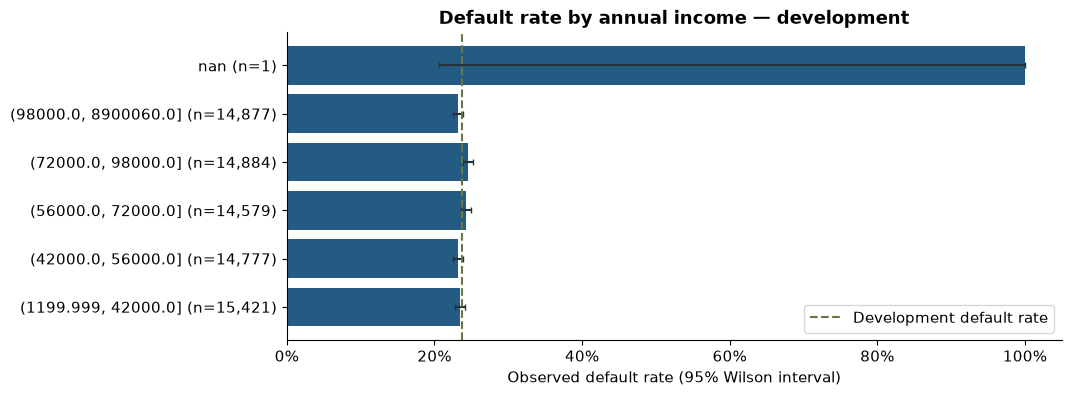

**Observed association:** among groups with at least 100 loans, **(72000.0, 98000.0]** has a default rate of **24.6%** versus **23.2%** for **(98000.0, 8900060.0]**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.

In [12]:
distribution_chart('annual_income', clip=True)
rate_chart('annual_income', bins=True);

### Debt To Income
Compare the source distribution with observed default rates by development-set quantiles. Currency fields retain the dictionary’s units.

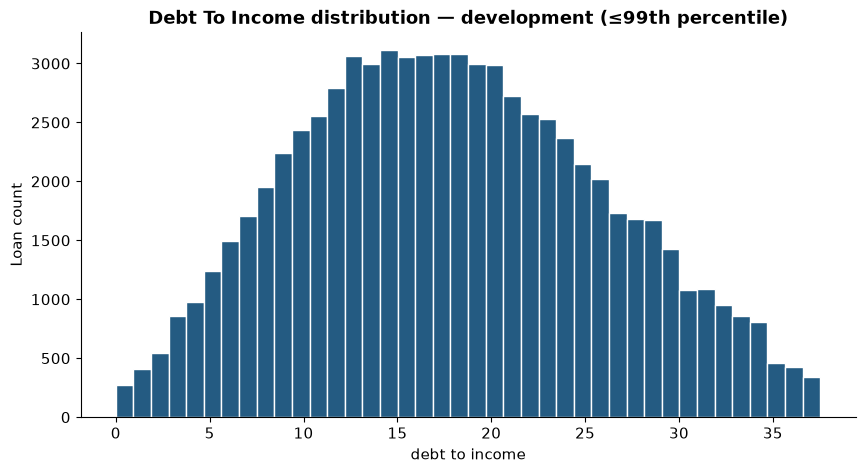

**Distribution:** median debt_to_income is **17.64**, compared with a 99th percentile of **37.53**. The plot displays **73,796** nonmissing observations; 743 upper-tail values are omitted from this view only. These descriptive values do not justify deleting extreme records.

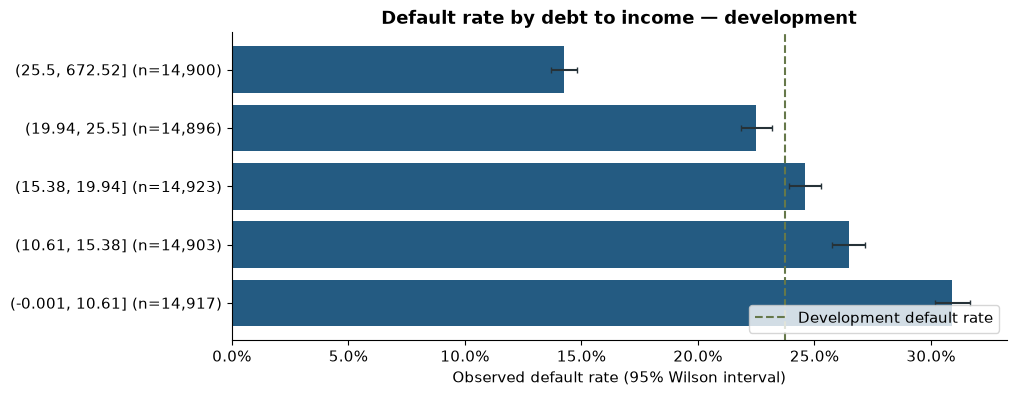

**Observed association:** among groups with at least 100 loans, **(-0.001, 10.61]** has a default rate of **30.9%** versus **14.3%** for **(25.5, 672.52]**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.

In [13]:
distribution_chart('debt_to_income', clip=True)
rate_chart('debt_to_income', bins=True);

### Loan grade and subgrade
Counts and intervals put observed group differences in context. Category labels preserve the supplied dictionary.

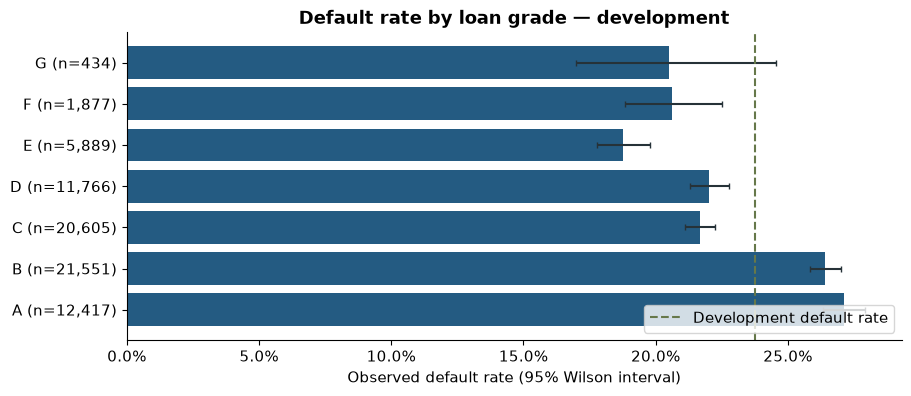

**Observed association:** among groups with at least 100 loans, **A** has a default rate of **27.1%** versus **18.8%** for **E**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.

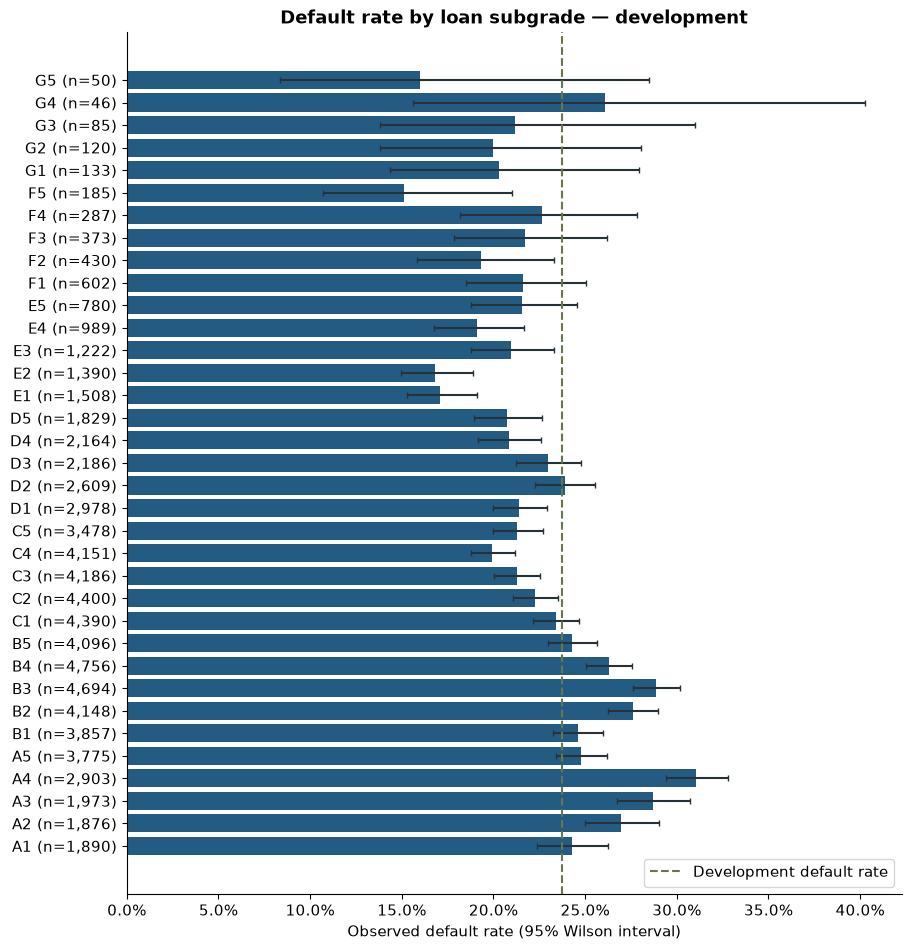

**Observed association:** among groups with at least 100 loans, **A4** has a default rate of **31.1%** versus **15.1%** for **F5**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.

In [14]:
rate_chart('loan_grade');
rate_chart('loan_subgrade');

### Loan duration
Counts and intervals put observed group differences in context. Category labels preserve the supplied dictionary.

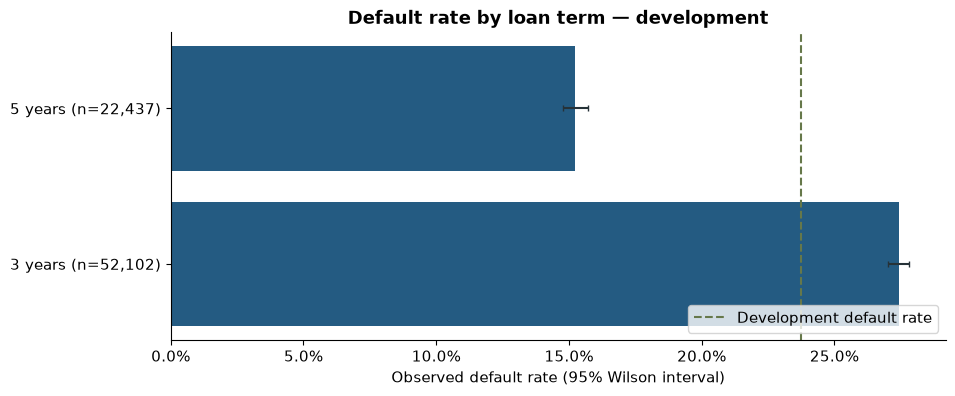

**Observed association:** among groups with at least 100 loans, **3 years** has a default rate of **27.4%** versus **15.2%** for **5 years**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.

In [15]:
rate_chart('loan_term');

### Borrowing purpose and housing
Counts and intervals put observed group differences in context. Category labels preserve the supplied dictionary.

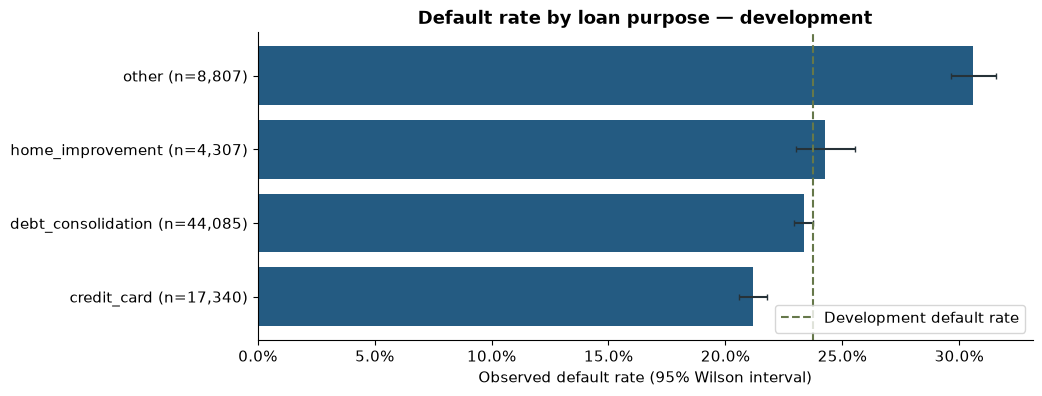

**Observed association:** among groups with at least 100 loans, **other** has a default rate of **30.6%** versus **21.2%** for **credit_card**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.

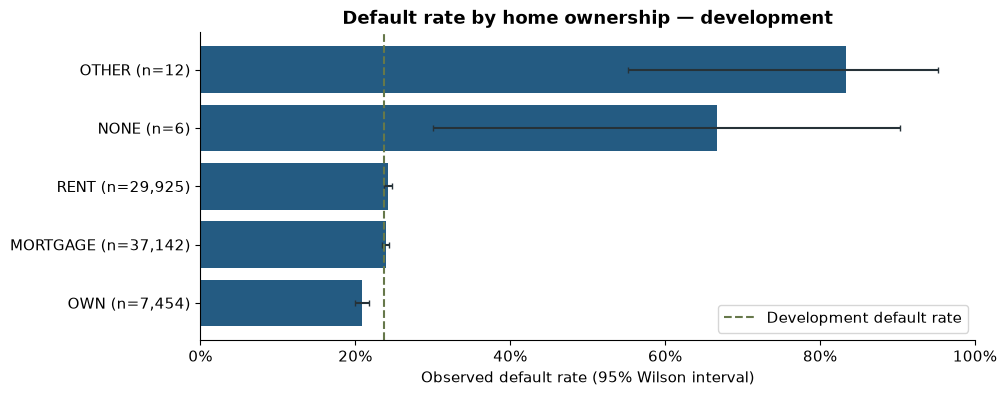

**Observed association:** among groups with at least 100 loans, **RENT** has a default rate of **24.2%** versus **20.8%** for **OWN**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.

In [16]:
rate_chart('loan_purpose');
rate_chart('home_ownership');

### Job experience
Counts and intervals put observed group differences in context. Category labels preserve the supplied dictionary.

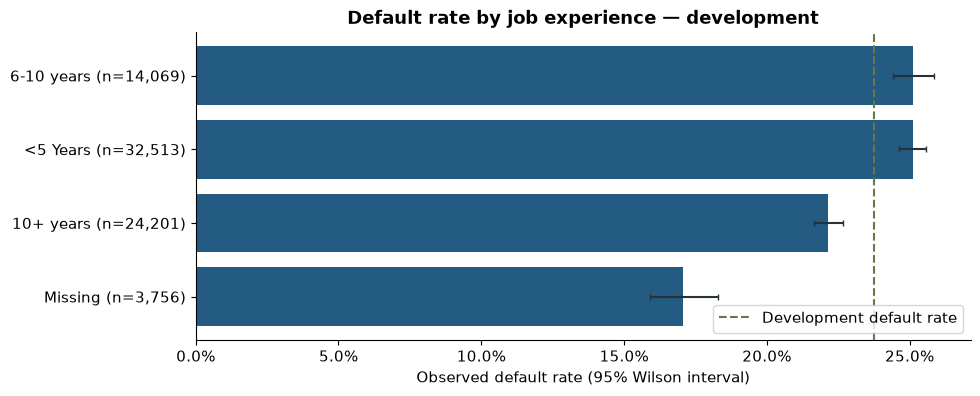

**Observed association:** among groups with at least 100 loans, **6-10 years** has a default rate of **25.1%** versus **17.1%** for **Missing**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.

In [17]:
rate_chart('job_experience');

### Delinquency and public records
The dictionary defines public records as legal cases. Counts are grouped into 0, 1, 2 and 3+ for readable charts only; model input retains the original counts.

,count,sum,mean,lower,upper
group,,,,,
0,60233,14822,0.246078,0.242654,0.249534
1,9457,1960,0.207254,0.199204,0.215542
2,2797,560,0.200215,0.185800,0.215451
3+,2050,359,0.175122,0.159281,0.192178
Missing,2,2,1.000000,0.342372,1.000000


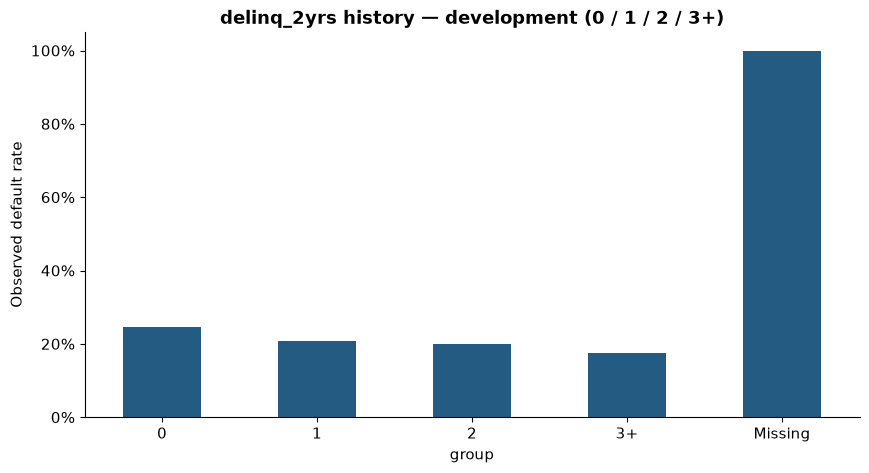

**Observed association:** rates range from **17.5%** to **100.0%** across the displayed history groups. Counts/intervals in the table qualify rare groups; past events are associated with outcomes, not proven to cause them.

,count,sum,mean,lower,upper
group,,,,,
0,63105,15516,0.245876,0.242532,0.249251
1,9509,1939,0.203912,0.195934,0.212129
2,1253,176,0.140463,0.122320,0.160803
3+,670,70,0.104478,0.083527,0.129938
Missing,2,2,1.000000,0.342372,1.000000


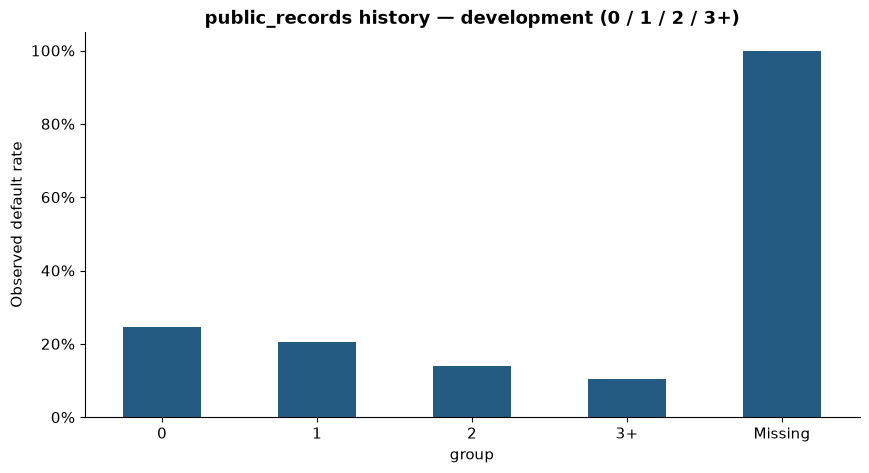

**Observed association:** rates range from **10.4%** to **100.0%** across the displayed history groups. Counts/intervals in the table qualify rare groups; past events are associated with outcomes, not proven to cause them.

In [18]:
for column in ['delinq_2yrs', 'public_records']:
    grouped = eda_df[column].map(lambda value: 'Missing' if pd.isna(value) else str(int(value)) if value < 3 else '3+')
    rates = grouped_rates(grouped)
    display(rates)
    ax = rates['mean'].plot.bar(rot=0)
    ax.set(ylabel='Observed default rate', title=f'{column} history — development (0 / 1 / 2 / 3+)')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    save_plot(f'eda_{column}_rates.png')
    display(Markdown(f'**Observed association:** rates range from **{rates["mean"].min():.1%}** to **{rates["mean"].max():.1%}** across the displayed history groups. Counts/intervals in the table qualify rare groups; past events are associated with outcomes, not proven to cause them.'))

### Revolving exposure and available limits
Credit limits and balances describe exposure; utilization can exceed 100% and zero limits make it undefined. Both the source fields and derived utilization are investigated without changing model values.

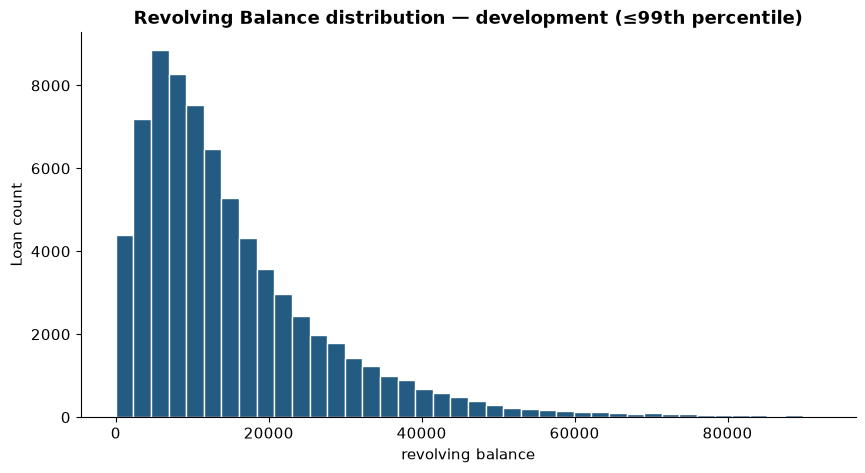

**Distribution:** median revolving_balance is **11,844.00**, compared with a 99th percentile of **92,155.98**. The plot displays **73,793** nonmissing observations; 746 upper-tail values are omitted from this view only. These descriptive values do not justify deleting extreme records.

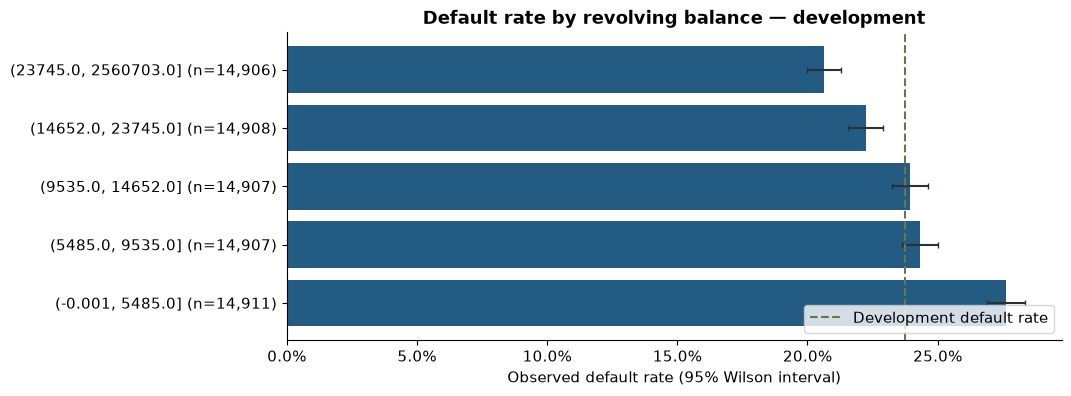

**Observed association:** among groups with at least 100 loans, **(-0.001, 5485.0]** has a default rate of **27.6%** versus **20.6%** for **(23745.0, 2560703.0]**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.

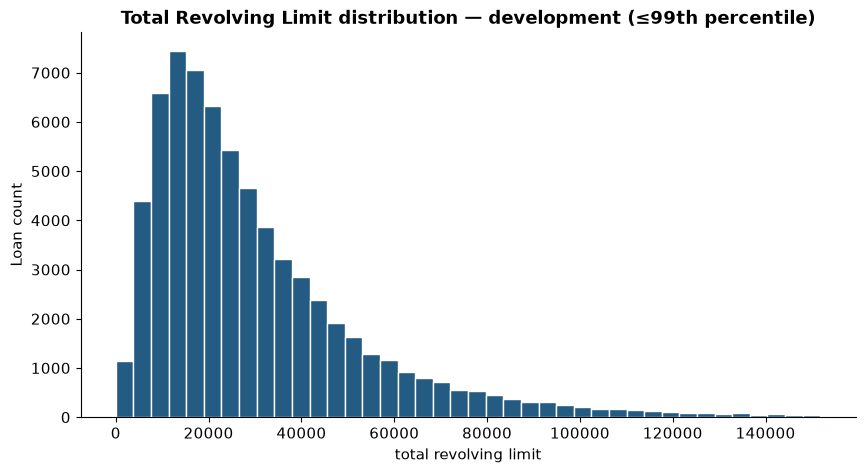

**Distribution:** median total_revolving_limit is **23,700.00**, compared with a 99th percentile of **151,843.20**. The plot displays **67,954** nonmissing observations; 687 upper-tail values are omitted from this view only. These descriptive values do not justify deleting extreme records.

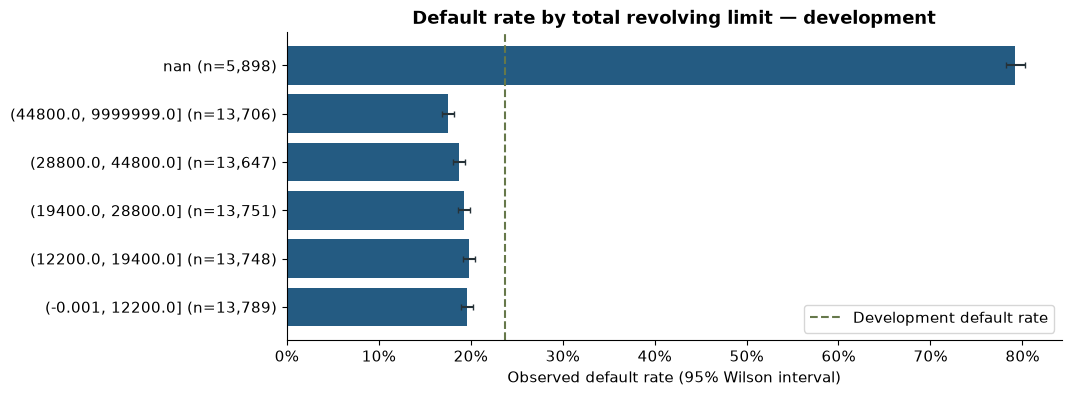

**Observed association:** among groups with at least 100 loans, **nan** has a default rate of **79.2%** versus **17.5%** for **(44800.0, 9999999.0]**. These differences may reflect borrower mix, loan vintage or dataset construction. Intervals for small groups are wider; no causal or lending-policy claim follows.

,credit_utilization
count,68612.000000
mean,0.554151
std,0.235098
min,0.000000
25%,0.381782
50%,0.560439
75%,0.736073
max,1.507097


,count,sum,mean,lower,upper
group,,,,,
"(-0.001, 0.339]",13723,2827,0.206005,0.199321,0.212853
"(0.339, 0.494]",13722,2592,0.188894,0.182432,0.195530
"(0.494, 0.629]",13722,2576,0.187728,0.181282,0.194349
"(0.629, 0.777]",13722,2624,0.191226,0.184732,0.197892
"(0.777, 1.507]",13723,2405,0.175253,0.168983,0.181705
NaN,5927,4679,0.789438,0.778873,0.799629


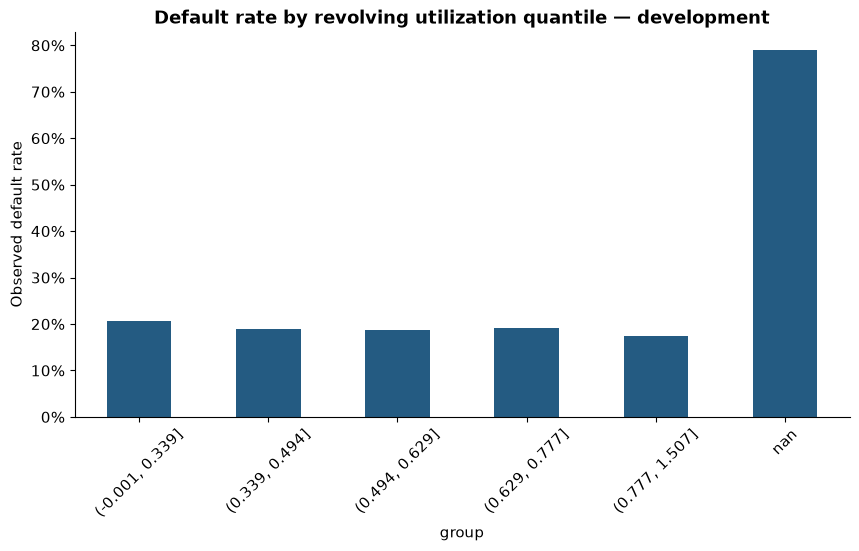

**Exposure interpretation:** utilization is undefined for **5,927** development loans. **282** have balances above their reported revolving limit. Quantile rates range from **17.5%** to **78.9%**; these are observed associations and warrant snapshot/definition checks before operational use.

In [19]:
distribution_chart('revolving_balance', clip=True)
rate_chart('revolving_balance', bins=True)
distribution_chart('total_revolving_limit', clip=True)
rate_chart('total_revolving_limit', bins=True)
utilization = create_features(eda_df)['credit_utilization']
display(utilization.describe().to_frame('credit_utilization'))
util_rates = grouped_rates(pd.qcut(utilization, 5, duplicates='drop'))
display(util_rates)
ax = util_rates['mean'].plot.bar(rot=45)
ax.set(title='Default rate by revolving utilization quantile — development', ylabel='Observed default rate')
ax.yaxis.set_major_formatter(PercentFormatter(1))
save_plot('eda_utilization_rates.png')
display(Markdown(f'**Exposure interpretation:** utilization is undefined for **{utilization.isna().sum():,}** development loans. **{(utilization > 1).sum():,}** have balances above their reported revolving limit. Quantile rates range from **{util_rates["mean"].min():.1%}** to **{util_rates["mean"].max():.1%}**; these are observed associations and warrant snapshot/definition checks before operational use.'))

## 9. Fit baseline and advanced models
The dummy classifier establishes the majority-class baseline. Logistic regression uses median imputation, missing indicators, scaling and one-hot encoding **inside a training-only pipeline**. Random forest uses the same encoding/imputation with bounded depth and leaf size. No oversampling or class weights are added initially: raw prevalence is retained for probability estimation and the decision threshold can adjust recall later.

Two modest CatBoost candidates use native categorical features, explicit missing-category strings and early stopping on the tuning subset. Candidate scores are development decisions, not final evaluation. No test labels or holdout outcomes enter fitting or tuning.

In [20]:
def make_preprocessor(scale=True):
    numeric_steps = [('impute', SimpleImputer(strategy='median', add_indicator=True))]
    if scale:
        numeric_steps.append(('scale', StandardScaler()))
    categorical_pipeline = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=True))])
    return ColumnTransformer([('numeric', Pipeline(numeric_steps), NUMERICAL_FEATURES),
        ('categorical', categorical_pipeline, CATEGORICAL_FEATURES)], sparse_threshold=1.0)

def evaluate_model(name, actual, probabilities, threshold=.5):
    """Return scalar metrics, hard predictions, probabilities and confusion matrix."""
    p = np.asarray(probabilities, dtype=float)
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    predicted = (p >= threshold).astype(int)
    metrics = {'Model': name, 'Threshold': float(threshold),
        'Accuracy': float(accuracy_score(actual, predicted)),
        'Precision': float(precision_score(actual, predicted, zero_division=0)),
        'Recall': float(recall_score(actual, predicted, zero_division=0)),
        'F1': float(f1_score(actual, predicted, zero_division=0)),
        'ROC-AUC': float(roc_auc_score(actual, p)),
        'PR-AUC': float(average_precision_score(actual, p)),
        'Brier': float(brier_score_loss(actual, p))}
    return {'metrics': metrics, 'predictions': predicted, 'probabilities': p,
        'confusion_matrix': confusion_matrix(actual, predicted, labels=[0, 1])}

models = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': Pipeline([('preprocessing', make_preprocessor()),
        ('model', LogisticRegression(C=.5, solver='lbfgs', max_iter=2500, random_state=RANDOM_STATE))]),
    'Random Forest': Pipeline([('preprocessing', make_preprocessor(scale=False)),
        ('model', RandomForestClassifier(n_estimators=180, max_depth=16, min_samples_leaf=20,
            max_features='sqrt', random_state=RANDOM_STATE, n_jobs=4))])}
tune_results = {}
fit_seconds = {}
for name, model in models.items():
    started = time.monotonic()
    model.fit(X_train, y_train)
    fit_seconds[name] = time.monotonic() - started
    tune_results[name] = evaluate_model(name, y_tune, model.predict_proba(X_tune)[:, 1])
    print(f'{name}: fit in {fit_seconds[name]:.1f}s')
display(pd.DataFrame([r['metrics'] for r in tune_results.values()]).round(4))

Dummy: fit in 0.0s


Logistic Regression: fit in 1.3s


Random Forest: fit in 11.5s


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier
0,Dummy,0.5,0.7625,0.0000,0.0000,0.0000,0.5000,0.2375,0.2375
1,Logistic Regression,0.5,0.8079,0.7174,0.3154,0.4382,0.8147,0.6075,0.1349
2,Random Forest,0.5,0.8049,0.7883,0.2440,0.3727,0.7798,0.5950,0.1443


In [21]:
catboost_trials = []
catboost_candidates = {}
for depth in [5, 7]:
    candidate = CatBoostClassifier(iterations=700, depth=depth, learning_rate=.05,
        loss_function='Logloss', eval_metric='AUC', random_seed=RANDOM_STATE,
        cat_features=CATEGORICAL_FEATURES, thread_count=4, l2_leaf_reg=5,
        allow_writing_files=False, verbose=False)
    started = time.monotonic()
    candidate.fit(X_train, y_train, eval_set=(X_tune, y_tune), early_stopping_rounds=70)
    result = evaluate_model(f'CatBoost depth {depth}', y_tune, candidate.predict_proba(X_tune)[:, 1])
    catboost_candidates[depth] = candidate
    catboost_trials.append({**result['metrics'], 'depth': depth,
        'trees': candidate.tree_count_, 'fit_seconds': time.monotonic()-started})
    print(f'CatBoost depth={depth}: {candidate.tree_count_} retained trees')
catboost_trial_table = pd.DataFrame(catboost_trials).sort_values(['ROC-AUC', 'PR-AUC'], ascending=False)
display(catboost_trial_table.round(4))
catboost_trial_table.to_csv(METRICS / 'catboost_trials.csv', index=False)
best_depth = int(catboost_trial_table.iloc[0]['depth'])
catboost_model = catboost_candidates[best_depth]
models['CatBoost'] = catboost_model
tune_results['CatBoost'] = evaluate_model('CatBoost', y_tune, catboost_model.predict_proba(X_tune)[:, 1])
development_comparison = pd.DataFrame([r['metrics'] for r in tune_results.values()]).sort_values(
    ['ROC-AUC', 'PR-AUC', 'F1', 'Recall'], ascending=False)
display(development_comparison.round(4))
development_comparison.to_csv(METRICS / 'development_model_comparison.csv', index=False)
selected_name = str(development_comparison.iloc[0]['Model'])
selected_model = models[selected_name]
display(Markdown(f'**Frozen model family: {selected_name}.** It ranks first on tuning ROC-AUC (**{development_comparison.iloc[0]["ROC-AUC"]:.4f}**), with average precision (**{development_comparison.iloc[0]["PR-AUC"]:.4f}**) as the secondary ranking criterion and F1/recall as further tie-breakers. All candidates are origination models with the same input scope. Calibration is evaluated next; interpretability and operational constraints are documented rather than assigned invented numerical weights. This selection precedes holdout scoring, so holdout ranking will not trigger reselection.'))

CatBoost depth=5: 700 retained trees


CatBoost depth=7: 682 retained trees


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,depth,trees,fit_seconds
1,CatBoost depth 7,0.5,0.8174,0.7144,0.3854,0.5007,0.8383,0.659,0.1262,7,682,139.328
0,CatBoost depth 5,0.5,0.8175,0.7244,0.3742,0.4934,0.8359,0.653,0.1271,5,700,122.766


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier
3,CatBoost,0.5,0.8174,0.7144,0.3854,0.5007,0.8383,0.6590,0.1262
1,Logistic Regression,0.5,0.8079,0.7174,0.3154,0.4382,0.8147,0.6075,0.1349
2,Random Forest,0.5,0.8049,0.7883,0.2440,0.3727,0.7798,0.5950,0.1443
0,Dummy,0.5,0.7625,0.0000,0.0000,0.0000,0.5000,0.2375,0.2375


**Frozen model family: CatBoost.** It ranks first on tuning ROC-AUC (**0.8383**), with average precision (**0.6590**) as the secondary ranking criterion and F1/recall as further tie-breakers. All candidates are origination models with the same input scope. Calibration is evaluated next; interpretability and operational constraints are documented rather than assigned invented numerical weights. This selection precedes holdout scoring, so holdout ranking will not trigger reselection.

## 10. Probability reliability and calibration choice
Fit sigmoid (Platt-style log-odds mapping) and isotonic mappings on calibration-fit rows. Compare both with unchanged probabilities on independent calibration-check rows. Retain calibration only when it reduces check-set Brier score by at least 1% relative to the uncalibrated score; this is a declared practical improvement rule, not a significance test. Brier measures squared probability error and reflects both calibration and discrimination. Reliability curves directly compare predicted and observed rates.

References: [scikit-learn calibration guide](https://scikit-learn.org/stable/modules/calibration.html). Small-bin sample sizes and finite-sample variation remain limitations.

,Brier,ROC-AUC,PR-AUC
method,,,
none,0.12535,0.83967,0.66297
sigmoid,0.12539,0.83967,0.66297
isotonic,0.12587,0.83876,0.64378


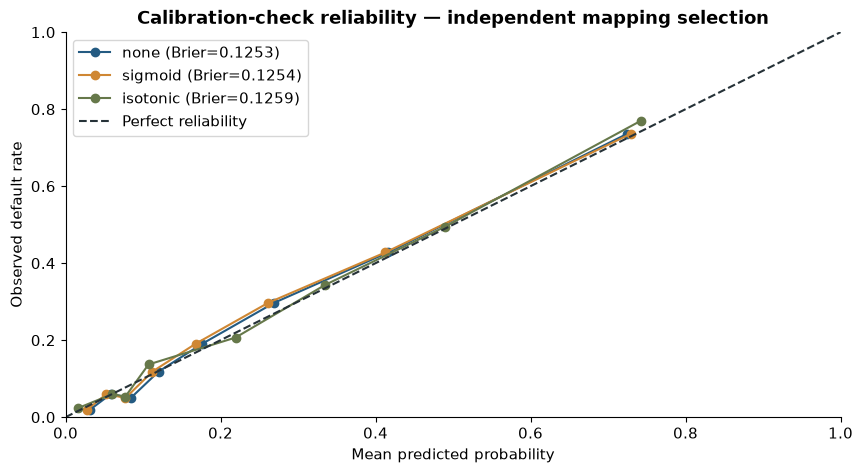

**Selected probability mapping: none.** Check-set Brier changes from **0.12535** to **0.12535**. Only the retained mapping will be used for thresholding, bands and deployment. Holdout labels did not participate.

In [22]:
calibration_base_fit = selected_model.predict_proba(X.loc[cal_fit_index])[:, 1]
calibration_base_check = selected_model.predict_proba(X.loc[cal_check_index])[:, 1]
sigmoid = LogisticRegression(C=1e6, random_state=RANDOM_STATE, max_iter=1000)
sigmoid.fit(probability_input(calibration_base_fit), y.loc[cal_fit_index])
isotonic = IsotonicRegression(out_of_bounds='clip')
isotonic.fit(calibration_base_fit, y.loc[cal_fit_index])
calibrators = {'none': None, 'sigmoid': sigmoid, 'isotonic': isotonic}
calibration_check_probs = {method: calibrated_probability(selected_model, X.loc[cal_check_index], cal, method)
    for method, cal in calibrators.items()}
calibration_comparison = pd.DataFrame([{'method': method,
    'Brier': brier_score_loss(y.loc[cal_check_index], p),
    'ROC-AUC': roc_auc_score(y.loc[cal_check_index], p),
    'PR-AUC': average_precision_score(y.loc[cal_check_index], p)}
    for method, p in calibration_check_probs.items()]).set_index('method')
display(calibration_comparison.round(5))
calibration_comparison.to_csv(METRICS / 'calibration_comparison.csv')
best_calibration = calibration_comparison.Brier.idxmin()
base_brier = calibration_comparison.loc['none', 'Brier']
calibration_method = best_calibration if calibration_comparison.loc[best_calibration, 'Brier'] < base_brier * .99 else 'none'
selected_calibrator = calibrators[calibration_method]
fig, ax = plt.subplots()
for method, p in calibration_check_probs.items():
    observed, predicted = calibration_curve(y.loc[cal_check_index], p, n_bins=8, strategy='quantile')
    ax.plot(predicted, observed, marker='o', label=f'{method} (Brier={calibration_comparison.loc[method,"Brier"]:.4f})')
ax.plot([0, 1], [0, 1], '--', color='#263238', label='Perfect reliability')
ax.set(xlabel='Mean predicted probability', ylabel='Observed default rate',
    title='Calibration-check reliability — independent mapping selection', xlim=(0, 1), ylim=(0, 1))
ax.legend()
save_plot('calibration_selection.png')
display(Markdown(f'**Selected probability mapping: {calibration_method}.** Check-set Brier changes from **{base_brier:.5f}** to **{calibration_comparison.loc[calibration_method,"Brier"]:.5f}**. Only the retained mapping will be used for thresholding, bands and deployment. Holdout labels did not participate.'))

## 11. Freeze the operating threshold and risk bands
Thresholds 0.10–0.90 are compared on tuning rows with the retained probability mapping. Select the highest tuning F1; ties prefer recall then precision. This educational objective balances precision and recall without pretending to know lending costs. An NBFC would choose a threshold from the costs of missed defaults, unnecessary flags and risk appetite, then validate it prospectively.

Risk bands use the tuning probability median, the selected threshold and the 90th percentile as three ordered boundaries. If these collide, distinct tuning quantiles (25%, 50%, 75%) provide a documented fallback. These are initial segmentation bands, not universal credit grades.

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,False Positives,False Negatives,True Positives,True Negatives
0,CatBoost,0.10,0.5691,0.3475,0.9277,0.5056,0.8383,0.659,0.1262,3855,160,2053,3249
5,CatBoost,0.15,0.6861,0.4214,0.8626,0.5662,0.8383,0.659,0.1262,2621,304,1909,4483
10,CatBoost,0.20,0.7485,0.4821,0.7921,0.5994,0.8383,0.659,0.1262,1883,460,1753,5221
15,CatBoost,0.25,0.7807,0.5279,0.7262,0.6114,0.8383,0.659,0.1262,1437,606,1607,5667
20,CatBoost,0.30,0.8004,0.5680,0.6665,0.6133,0.8383,0.659,0.1262,1122,738,1475,5982
25,CatBoost,0.35,0.8112,0.6030,0.6005,0.6018,0.8383,0.659,0.1262,875,884,1329,6229
30,CatBoost,0.40,0.8180,0.6431,0.5251,0.5781,0.8383,0.659,0.1262,645,1051,1162,6459
35,CatBoost,0.45,0.8182,0.6764,0.4496,0.5402,0.8383,0.659,0.1262,476,1218,995,6628
40,CatBoost,0.50,0.8174,0.7144,0.3854,0.5007,0.8383,0.659,0.1262,341,1360,853,6763
45,CatBoost,0.55,0.8165,0.7569,0.3348,0.4643,0.8383,0.659,0.1262,238,1472,741,6866


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,False Positives,False Negatives,True Positives,True Negatives
18,CatBoost,0.28,0.7952,0.5552,0.6936,0.6167,0.8383,0.659,0.1262,1230,678,1535,5874


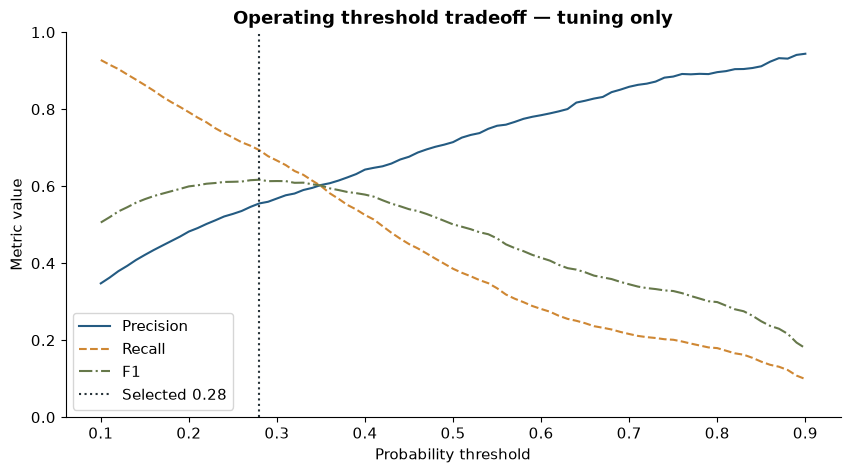

,band,lower,upper
0,Low,0.00000,0.14465
1,Moderate,0.14465,0.28000
2,High,0.28000,0.55951
3,Very High,0.55951,1.00000


**Frozen threshold: 0.28.** Risk boundaries are **0.1446, 0.2800, 0.5595**, derived from sorted tuning median, F1 threshold, tuning 90th percentile. Neither threshold nor bands will be revised after examining holdout outcomes.

In [23]:
tune_probabilities = calibrated_probability(selected_model, X_tune, selected_calibrator, calibration_method)
threshold_rows = []
for threshold in np.round(np.arange(.10, .901, .01), 2):
    result = evaluate_model(selected_name, y_tune, tune_probabilities, threshold)
    tn, fp, fn, tp = result['confusion_matrix'].ravel()
    threshold_rows.append({**result['metrics'], 'False Positives': int(fp), 'False Negatives': int(fn),
        'True Positives': int(tp), 'True Negatives': int(tn)})
threshold_analysis = pd.DataFrame(threshold_rows)
selected_threshold = float(threshold_analysis.sort_values(['F1', 'Recall', 'Precision'], ascending=False).iloc[0].Threshold)
display(threshold_analysis.iloc[::5].round(4))
display(threshold_analysis.loc[threshold_analysis.Threshold == selected_threshold].round(4))
threshold_analysis.to_csv(METRICS / 'threshold_analysis.csv', index=False)
fig, ax = plt.subplots()
for metric, style in [('Precision', '-'), ('Recall', '--'), ('F1', '-.')]:
    ax.plot(threshold_analysis.Threshold, threshold_analysis[metric], linestyle=style, label=metric)
ax.axvline(selected_threshold, color='#263238', linestyle=':', label=f'Selected {selected_threshold:.2f}')
ax.set(xlabel='Probability threshold', ylabel='Metric value', title='Operating threshold tradeoff — tuning only', ylim=(0, 1))
ax.legend()
save_plot('threshold_analysis.png')
boundaries = sorted([float(np.quantile(tune_probabilities, .50)), selected_threshold,
    float(np.quantile(tune_probabilities, .90))])
band_method = 'sorted tuning median, F1 threshold, tuning 90th percentile'
if min(np.diff(boundaries)) < 1e-5 or boundaries[0] <= 0 or boundaries[-1] >= 1:
    boundaries = np.quantile(tune_probabilities, [.25, .50, .75]).tolist()
    band_method = 'fallback tuning quartiles after coincident/degenerate primary boundaries'
assert 0 < boundaries[0] < boundaries[1] < boundaries[2] < 1
band_names = ['Low', 'Moderate', 'High', 'Very High']
band_edges = [0., *boundaries, 1.]
risk_config = {'boundaries': boundaries, 'names': band_names, 'derivation': band_method,
    'interval_convention': 'left closed, right open; final interval includes 1',
    'ranges': {name: [band_edges[i], band_edges[i+1]] for i, name in enumerate(band_names)}}
display(pd.DataFrame({'band': band_names, 'lower': band_edges[:-1], 'upper': band_edges[1:]}))
display(Markdown(f'**Frozen threshold: {selected_threshold:.2f}.** Risk boundaries are **{boundaries[0]:.4f}, {boundaries[1]:.4f}, {boundaries[2]:.4f}**, derived from {band_method}. Neither threshold nor bands will be revised after examining holdout outcomes.'))

## 12. One-time untouched holdout evaluation
Every family is scored on the same held-out rows at 0.50. The selected model is additionally evaluated using its frozen mapping and threshold. PR-AUC here means **average precision** (a recall-weighted precision summary), not trapezoidal integration. Holdout metrics evaluate the frozen development procedure; they do not estimate the subsequently refitted all-data model directly.

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier
0,Dummy,0.50,0.7625,0.0000,0.0000,0.0000,0.5000,0.2375,0.2375
1,Logistic Regression,0.50,0.8124,0.7333,0.3305,0.4557,0.8187,0.6271,0.1325
2,Random Forest,0.50,0.8134,0.8233,0.2727,0.4097,0.7903,0.6170,0.1397
3,CatBoost,0.50,0.8257,0.7364,0.4141,0.5302,0.8440,0.6751,0.1229
4,CatBoost — selected operating point,0.28,0.7928,0.5500,0.7004,0.6162,0.8440,0.6751,0.1229


### Selected model classification report

               precision    recall  f1-score   support

Non-Defaulter       0.90      0.82      0.86     14209
    Defaulter       0.55      0.70      0.62      4426

     accuracy                           0.79     18635
    macro avg       0.72      0.76      0.74     18635
 weighted avg       0.82      0.79      0.80     18635



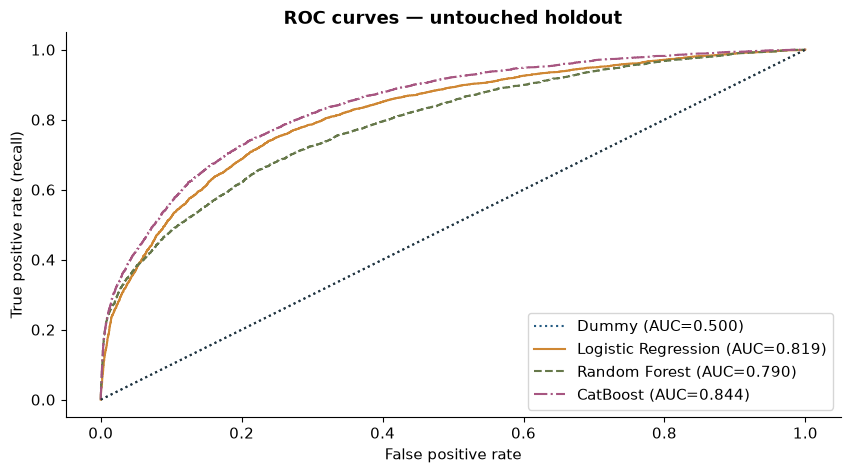

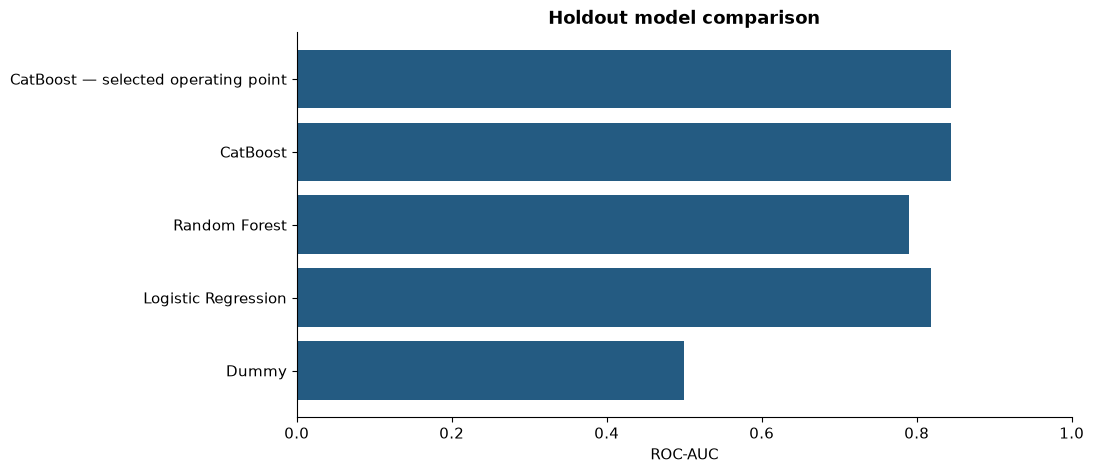

In [24]:
validation_results = {name: evaluate_model(name, y_valid, model.predict_proba(X_valid)[:, 1])
    for name, model in models.items()}
final_valid_probabilities = calibrated_probability(selected_model, X_valid, selected_calibrator, calibration_method)
final_result = evaluate_model(f'{selected_name} — selected operating point', y_valid,
    final_valid_probabilities, selected_threshold)
model_comparison = pd.DataFrame([r['metrics'] for r in validation_results.values()] + [final_result['metrics']])
display(model_comparison.round(4))
model_comparison.to_csv(METRICS / 'model_comparison.csv', index=False)
display(Markdown('### Selected model classification report'))
print(classification_report(y_valid, final_result['predictions'], target_names=['Non-Defaulter', 'Defaulter'], zero_division=0))
fig, ax = plt.subplots()
for i, (name, result) in enumerate(validation_results.items()):
    fpr, tpr, _ = roc_curve(y_valid, result['probabilities'])
    ax.plot(fpr, tpr, linestyle=[':', '-', '--', '-.'][i], label=f'{name} (AUC={result["metrics"]["ROC-AUC"]:.3f})')
ax.plot([0, 1], [0, 1], ':', color='#263238')
ax.set(xlabel='False positive rate', ylabel='True positive rate (recall)', title='ROC curves — untouched holdout')
ax.legend()
save_plot('roc_curve.png')
fig, ax = plt.subplots()
names = model_comparison.Model.tolist()
ax.barh(names, model_comparison['ROC-AUC'], label='ROC-AUC', color='#245B82')
ax.set(xlabel='ROC-AUC', title='Holdout model comparison', xlim=(0, 1))
save_plot('model_comparison.png')

### Confusion matrices and business meaning
A false negative is an actual defaulter predicted as non-default; a false positive is a non-defaulter flagged as high risk. Their relative business costs are unknown, which is why the F1 threshold is illustrative. Each matrix states the operating threshold.

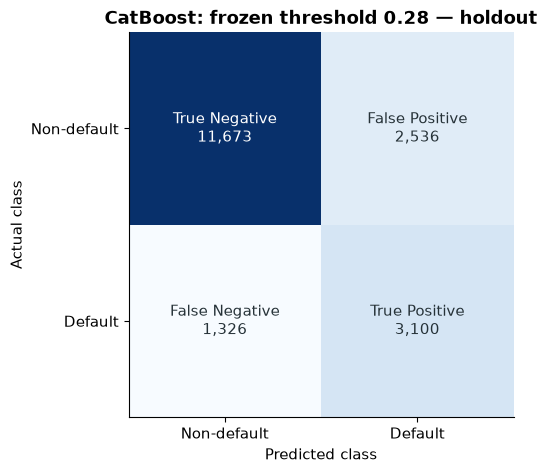

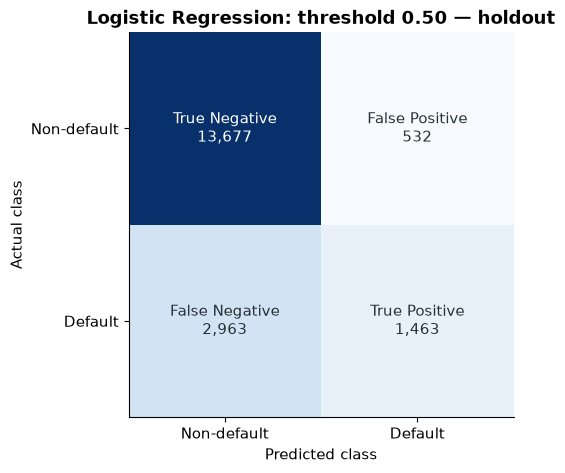

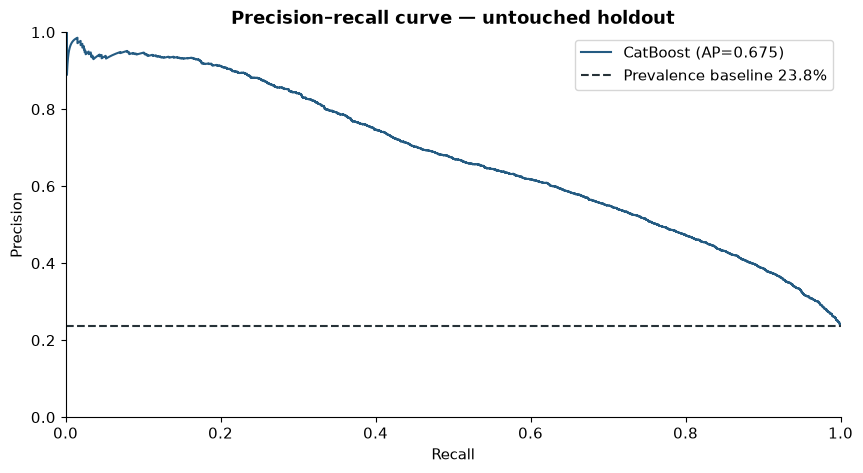

**Average precision is 0.6751**, compared with holdout prevalence **0.2375**. It summarizes how concentrated defaults are among higher-scored borrowers and is informative when non-defaults dominate. The threshold tradeoff remains separate from ranking quality.

In [25]:
def draw_confusion(result, title, filename):
    fig, ax = plt.subplots(figsize=(6, 5))
    cm = result['confusion_matrix']
    ax.imshow(cm, cmap='Blues')
    labels = [['True Negative', 'False Positive'], ['False Negative', 'True Positive']]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{labels[i][j]}\n{cm[i,j]:,}', ha='center', va='center',
                color='white' if cm[i,j] > cm.max()/2 else '#263238')
    ax.set(xticks=[0,1], yticks=[0,1], xticklabels=['Non-default', 'Default'],
        yticklabels=['Non-default', 'Default'], xlabel='Predicted class', ylabel='Actual class', title=title)
    save_plot(filename)

draw_confusion(final_result, f'{selected_name}: frozen threshold {selected_threshold:.2f} — holdout', 'confusion_matrix.png')
runner_up = development_comparison.iloc[1]['Model']
draw_confusion(validation_results[runner_up], f'{runner_up}: threshold 0.50 — holdout', 'confusion_matrix_runner_up.png')
precision, recall, _ = precision_recall_curve(y_valid, final_valid_probabilities)
fig, ax = plt.subplots()
ax.plot(recall, precision, label=f'{selected_name} (AP={final_result["metrics"]["PR-AUC"]:.3f})')
ax.axhline(y_valid.mean(), linestyle='--', color='#263238', label=f'Prevalence baseline {y_valid.mean():.1%}')
ax.set(xlabel='Recall', ylabel='Precision', title='Precision–recall curve — untouched holdout', xlim=(0,1), ylim=(0,1))
ax.legend()
save_plot('precision_recall_curve.png')
display(Markdown(f'**Average precision is {final_result["metrics"]["PR-AUC"]:.4f}**, compared with holdout prevalence **{y_valid.mean():.4f}**. It summarizes how concentrated defaults are among higher-scored borrowers and is informative when non-defaults dominate. The threshold tradeoff remains separate from ranking quality.'))

### Credit-risk discrimination and probability reliability
Gini = 2 × ROC-AUC − 1. KS is the maximum absolute separation between the default and non-default score CDFs; equivalently the maximum absolute TPR−FPR gap at ROC thresholds. Both quantify ranking separation, not calibration or causality.

,value
Model,CatBoost — selected operating point
Threshold,0.28
Accuracy,0.792756
Precision,0.550035
Recall,0.700407
F1,0.61618
ROC-AUC,0.844031
PR-AUC,0.67506
Brier,0.12289
Gini,0.688062


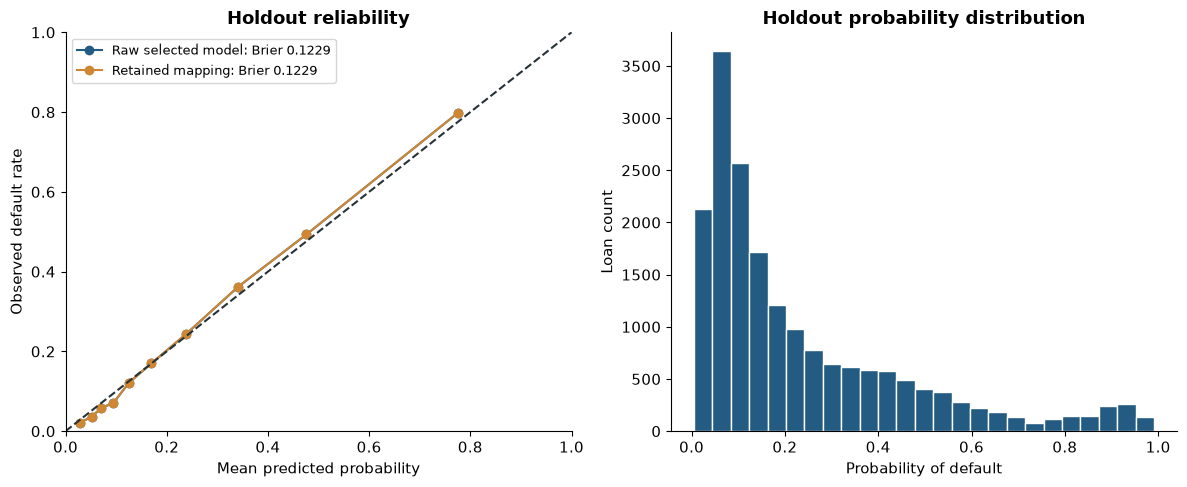

Holdout **Brier score: 0.12289**, **Gini: 0.6881**, **KS: 0.5295**. Calibration was chosen earlier; a different holdout reliability pattern is reported without retuning. A probability is conditional on this dataset and its unspecified outcome horizon.

In [26]:
def calculate_ks(actual, probabilities):
    """Tie-safe KS using the equivalent empirical ROC/CDF separation."""
    fpr, tpr, _ = roc_curve(actual, probabilities, drop_intermediate=False)
    return float(np.max(np.abs(tpr - fpr)))

final_metrics = dict(final_result['metrics'])
final_metrics['Gini'] = 2 * final_metrics['ROC-AUC'] - 1
final_metrics['KS'] = calculate_ks(y_valid, final_valid_probabilities)
final_metrics['evaluation_partition'] = 'untouched stratified 20% holdout'
final_metrics['calibration_method'] = calibration_method
final_metrics['holdout_rows'] = len(y_valid)
display(pd.Series(final_metrics).to_frame('value'))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
raw_valid_probabilities = validation_results[selected_name]['probabilities']
for label, p in [('Raw selected model', raw_valid_probabilities), ('Retained mapping', final_valid_probabilities)]:
    observed, predicted = calibration_curve(y_valid, p, n_bins=10, strategy='quantile')
    axes[0].plot(predicted, observed, marker='o', label=f'{label}: Brier {brier_score_loss(y_valid,p):.4f}')
axes[0].plot([0,1],[0,1], '--', color='#263238')
axes[0].set(xlabel='Mean predicted probability', ylabel='Observed default rate', title='Holdout reliability', xlim=(0,1), ylim=(0,1))
axes[0].legend(fontsize=9)
axes[1].hist(final_valid_probabilities, bins=25, color='#245B82', edgecolor='white')
axes[1].set(xlabel='Probability of default', ylabel='Loan count', title='Holdout probability distribution')
plt.tight_layout()
save_plot('calibration_curve.png')
display(Markdown(f'Holdout **Brier score: {final_metrics["Brier"]:.5f}**, **Gini: {final_metrics["Gini"]:.4f}**, **KS: {final_metrics["KS"]:.4f}**. Calibration was chosen earlier; a different holdout reliability pattern is reported without retuning. A probability is conditional on this dataset and its unspecified outcome horizon.'))
write_json(METRICS / 'final_model_metrics.json', final_metrics)
validation_predictions = pd.DataFrame({'ID': train_df.loc[validation_index, ID_COLUMN],
    'actual_default': y_valid, 'probability_of_default': final_valid_probabilities,
    'predicted_default': final_result['predictions']})
validation_predictions.to_csv(METRICS / 'validation_predictions.csv', index=False)

## 13. Holdout risk-band separation
Apply the previously frozen tuning-derived boundaries. Borrower counts, predicted probabilities and observed defaults show whether the bands separate risk. Bands are not adjusted to manufacture monotonicity.

,borrower_count,average_predicted_probability,observed_default_rate,defaults
risk_band,,,,
Low,9311,0.0741,0.0615,573
Moderate,3688,0.2026,0.2042,753
High,3718,0.4049,0.4242,1577
Very High,1918,0.7702,0.7941,1523


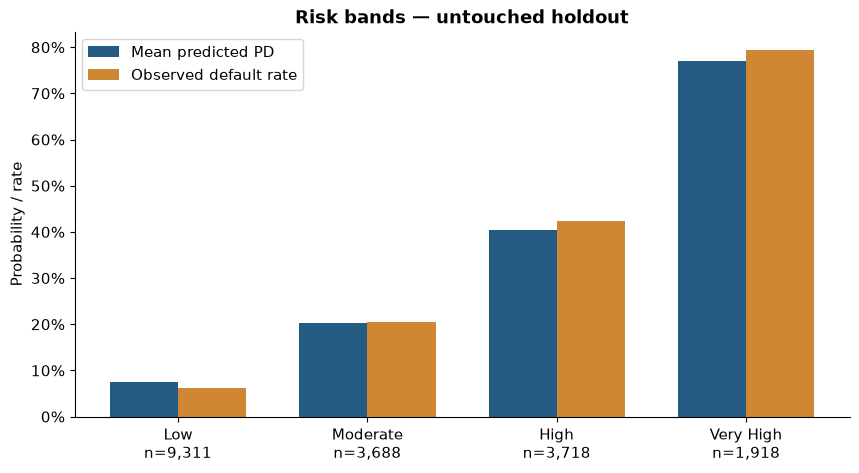

Observed holdout band rates are **monotonically increasing**. Low and Very High rates are **6.2%** and **79.4%**. Differences between predicted and observed rates reveal reliability gaps; sparse bands need additional validation.

In [27]:
validation_predictions['risk_band'] = pd.Categorical(
    [assign_risk_band(p, boundaries) for p in final_valid_probabilities], categories=band_names, ordered=True)
risk_band_table = validation_predictions.groupby('risk_band', observed=False).agg(
    borrower_count=('actual_default', 'size'),
    average_predicted_probability=('probability_of_default','mean'),
    observed_default_rate=('actual_default','mean'), defaults=('actual_default','sum'))
display(risk_band_table.round(4))
risk_band_table.to_csv(METRICS / 'risk_band_analysis.csv')
fig, ax = plt.subplots()
positions = np.arange(4)
ax.bar(positions-.18, risk_band_table.average_predicted_probability, width=.36, label='Mean predicted PD', color='#245B82')
ax.bar(positions+.18, risk_band_table.observed_default_rate, width=.36, label='Observed default rate', color='#CF8733')
ax.set(xticks=positions, xticklabels=[f'{b}\nn={n:,}' for b,n in zip(band_names,risk_band_table.borrower_count)],
    ylabel='Probability / rate', title='Risk bands — untouched holdout')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
save_plot('risk_band_analysis.png')
monotone = risk_band_table.observed_default_rate.dropna().is_monotonic_increasing
display(Markdown(f'Observed holdout band rates are **{"monotonically increasing" if monotone else "not monotonically increasing"}**. Low and Very High rates are **{risk_band_table.iloc[0].observed_default_rate:.1%}** and **{risk_band_table.iloc[-1].observed_default_rate:.1%}**. Differences between predicted and observed rates reveal reliability gaps; sparse bands need additional validation.'))

## 14. SHAP explainability
CatBoost computes actual SHAP values on a reproducible sample of up to 500 holdout borrowers. Global bars summarize mean absolute contribution; the beeswarm shows direction and variation. Categorical colors use sampled category codes solely for display, with mappings saved; they imply no numerical order. Individual explanations use the lowest, median and highest scored CatBoost holdout borrowers.

SHAP contributions sum with the expected value to the model’s **raw log odds**. They describe model associations, not causal effects. If a probability calibration mapping is retained, these contributions explain the underlying score and do not add directly in calibrated probability units. If another model family wins, this is explicitly a CatBoost challenger explanation, not an explanation of the deployed winner.

Reference: [CatBoost SHAP values](https://catboost.ai/docs/en/concepts/shap-values).

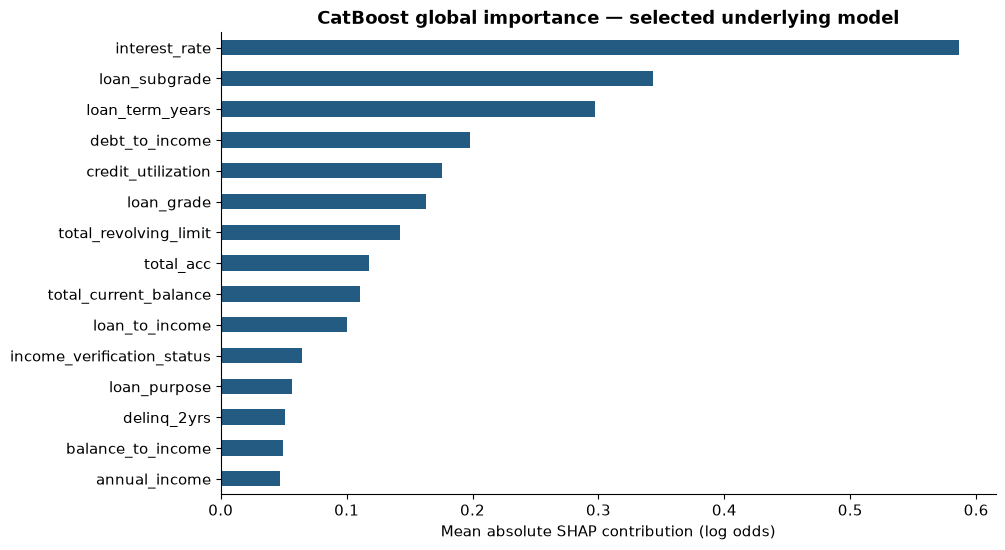

C:\Users\joshi\AppData\Local\Temp\ipykernel_15948\3271444700.py:21: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, shap_display, max_display=15, show=False, plot_size=(11, 7))


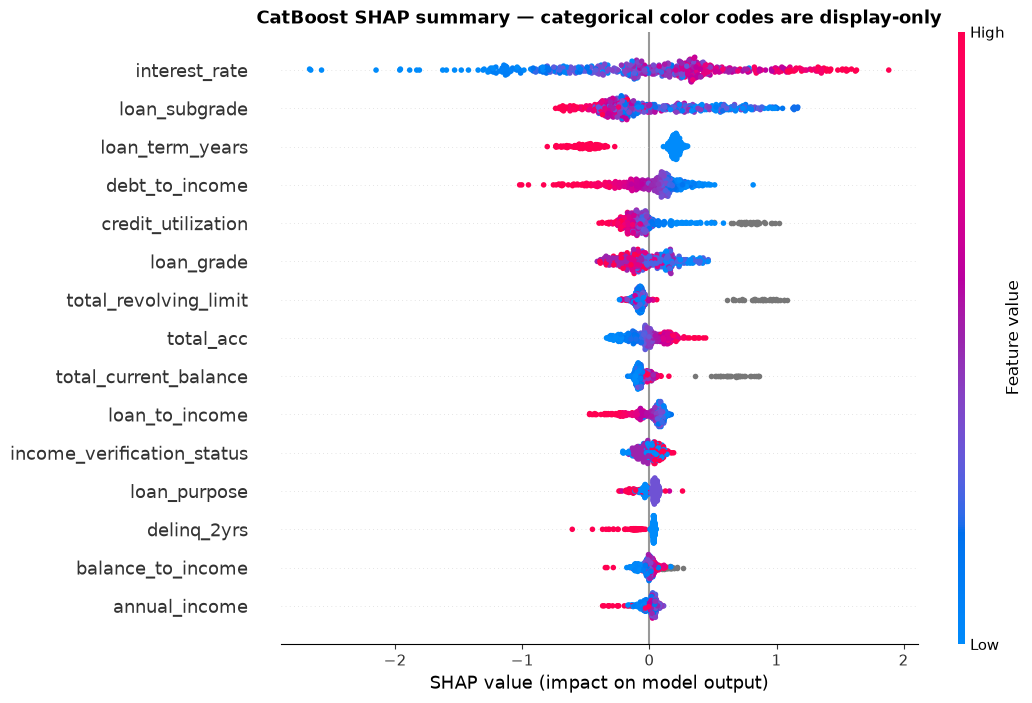

Top global associations are **interest_rate, loan_subgrade, loan_term_years, debt_to_income, credit_utilization**. Importance is measured on the displayed sample of **500** holdout loans. Correlated ratios, grades and source variables may share attribution; feature importance is not evidence of causation.

In [28]:
explanation_role = 'selected underlying model' if selected_name == 'CatBoost' else 'CatBoost challenger (not the selected family)'
shap_sample = X_valid.sample(n=min(500, len(X_valid)), random_state=RANDOM_STATE)
shap_pool = Pool(shap_sample, cat_features=CATEGORICAL_FEATURES)
shap_matrix = catboost_model.get_feature_importance(shap_pool, type='ShapValues')
shap_values, expected_values = shap_matrix[:, :-1], shap_matrix[:, -1]
raw_scores = catboost_model.predict(shap_sample, prediction_type='RawFormulaVal')
np.testing.assert_allclose(shap_values.sum(axis=1) + expected_values, raw_scores, atol=1e-6)
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURE_COLUMNS).sort_values(ascending=False)
shap_importance.to_csv(METRICS / 'shap_global_importance.csv', header=['mean_absolute_shap'])
fig, ax = plt.subplots(figsize=(10, 6))
shap_importance.head(15).sort_values().plot.barh(ax=ax, color='#245B82')
ax.set(xlabel='Mean absolute SHAP contribution (log odds)', title=f'CatBoost global importance — {explanation_role}')
save_plot('feature_importance.png')
shap_display = shap_sample.copy()
categorical_color_codes = {}
for c in CATEGORICAL_FEATURES:
    categories = sorted(shap_sample[c].unique())
    categorical_color_codes[c] = {category: i for i, category in enumerate(categories)}
    shap_display[c] = shap_sample[c].map(categorical_color_codes[c]).astype(float)
write_json(METRICS / 'shap_categorical_color_codes.json', categorical_color_codes)
shap.summary_plot(shap_values, shap_display, max_display=15, show=False, plot_size=(11, 7))
plt.title('CatBoost SHAP summary — categorical color codes are display-only')
save_plot('shap_summary.png')
display(Markdown(f'Top global associations are **{", ".join(shap_importance.head(5).index)}**. Importance is measured on the displayed sample of **{len(shap_sample):,}** holdout loans. Correlated ratios, grades and source variables may share attribution; feature importance is not evidence of causation.'))

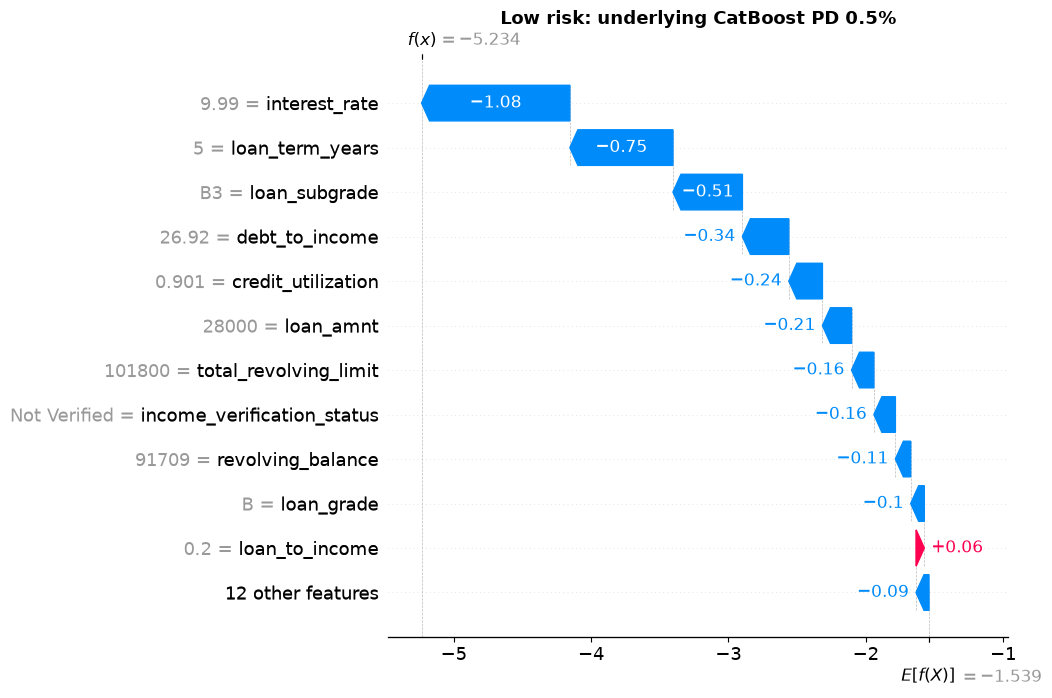

,feature,value,shap_log_odds,example,ID
1,interest_rate,9.99,-1.079773,Low risk,63069118
18,loan_term_years,5.0,-0.750597,Low risk,63069118
3,loan_subgrade,B3,-0.505497,Low risk,63069118
10,debt_to_income,26.92,-0.337825,Low risk,63069118
20,credit_utilization,0.9008742632612967,-0.244874,Low risk,63069118
0,loan_amnt,28000.0,-0.211789,Low risk,63069118
17,total_revolving_limit,101800.0,-0.162859,Low risk,63069118
7,income_verification_status,Not Verified,-0.156539,Low risk,63069118


**Low risk:** positive log-odds contributions include **loan_to_income, home_ownership, delinq_2yrs**; negative contributions include **interest_rate, loan_term_years, loan_subgrade**. These are actual borrower-specific score associations for the selected underlying model.

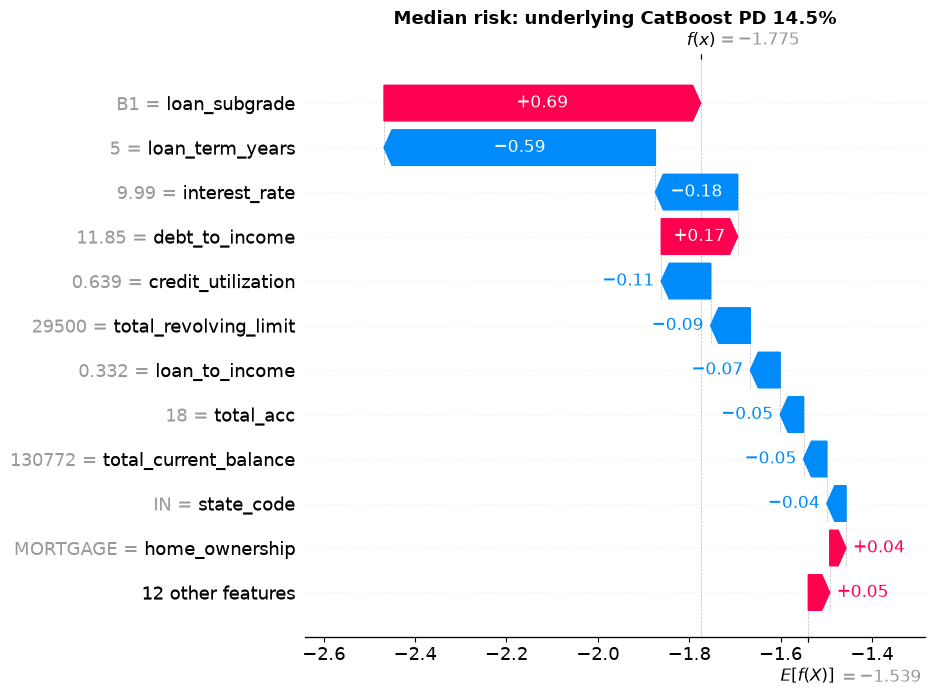

,feature,value,shap_log_odds,example,ID
3,loan_subgrade,B1,0.693117,Median risk,8541493
18,loan_term_years,5.0,-0.594147,Median risk,8541493
1,interest_rate,9.99,-0.179874,Median risk,8541493
10,debt_to_income,11.85,0.167094,Median risk,8541493
20,credit_utilization,0.6386101694915254,-0.108133,Median risk,8541493
17,total_revolving_limit,29500.0,-0.086938,Median risk,8541493
19,loan_to_income,0.3323076923076923,-0.065280,Median risk,8541493
14,total_acc,18.0,-0.051122,Median risk,8541493


**Median risk:** positive log-odds contributions include **loan_subgrade, debt_to_income, home_ownership**; negative contributions include **loan_term_years, interest_rate, credit_utilization**. These are actual borrower-specific score associations for the selected underlying model.

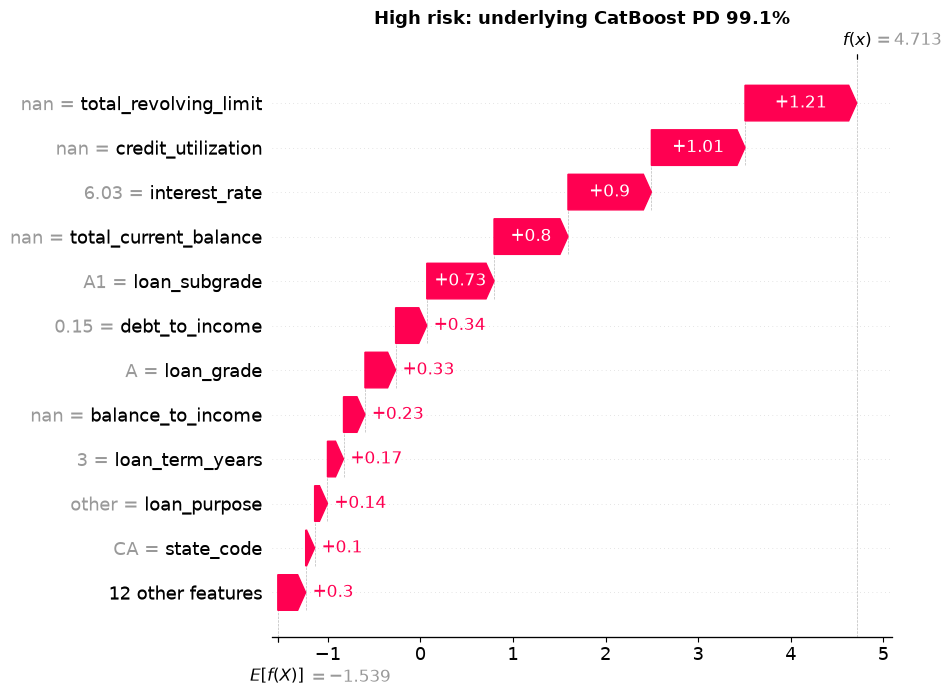

,feature,value,shap_log_odds,example,ID
17,total_revolving_limit,NaN,1.206414,High risk,1098870
20,credit_utilization,NaN,1.011133,High risk,1098870
1,interest_rate,6.03,0.900754,High risk,1098870
16,total_current_balance,NaN,0.798612,High risk,1098870
3,loan_subgrade,A1,0.726254,High risk,1098870
10,debt_to_income,0.15,0.336542,High risk,1098870
2,loan_grade,A,0.331149,High risk,1098870
21,balance_to_income,NaN,0.231679,High risk,1098870


**High risk:** positive log-odds contributions include **total_revolving_limit, credit_utilization, interest_rate**; negative contributions include **revolving_balance, loan_amnt, home_ownership**. These are actual borrower-specific score associations for the selected underlying model.

In [29]:
catboost_holdout_probability = catboost_model.predict_proba(X_valid)[:, 1]
ordered = np.argsort(catboost_holdout_probability)
example_positions = {'Low risk': int(ordered[0]), 'Median risk': int(ordered[len(ordered)//2]),
    'High risk': int(ordered[-1])}
individual_tables = []
for label, position in example_positions.items():
    row = X_valid.iloc[[position]]
    values = catboost_model.get_feature_importance(Pool(row, cat_features=CATEGORICAL_FEATURES), type='ShapValues')[0]
    raw = float(catboost_model.predict(row, prediction_type='RawFormulaVal')[0])
    np.testing.assert_allclose(values[:-1].sum() + values[-1], raw, atol=1e-6)
    explanation = shap.Explanation(values=values[:-1], base_values=float(values[-1]),
        data=row.iloc[0].to_numpy(), feature_names=FEATURE_COLUMNS)
    shap.plots.waterfall(explanation, max_display=12, show=False)
    plt.title(f'{label}: underlying CatBoost PD {catboost_holdout_probability[position]:.1%}')
    save_plot(f'shap_individual_{label.lower().replace(" ", "_")}.png')
    table = pd.DataFrame({'feature': FEATURE_COLUMNS, 'value': row.iloc[0].astype(str).to_numpy(),
        'shap_log_odds': values[:-1]}).sort_values('shap_log_odds', key=abs, ascending=False)
    table['example'] = label
    table['ID'] = int(train_df.loc[row.index[0], ID_COLUMN])
    individual_tables.append(table)
    display(table.head(8))
    positive = table[table.shap_log_odds > 0].head(3).feature.tolist()
    negative = table[table.shap_log_odds < 0].head(3).feature.tolist()
    display(Markdown(f'**{label}:** positive log-odds contributions include **{", ".join(positive)}**; negative contributions include **{", ".join(negative)}**. These are actual borrower-specific score associations for the {explanation_role}.'))
pd.concat(individual_tables).to_csv(METRICS / 'shap_individual_explanations.csv', index=False)

## 15. Optional existing-loan comparison
**Existing Loan Early Warning Model** includes repayment history solely as a separate sensitivity experiment. It uses the same fit/tune/holdout partition and does not replace or alter the origination pipeline. Any improvement may reflect later information or outcome-window contamination. Without observation dates and future default horizons, this is not a validated early-warning system.

In [30]:
RUN_MONITORING_COMPARISON = True
if RUN_MONITORING_COMPARISON:
    monitoring_features = X.copy()
    for column in post_loan:
        monitoring_features[column] = pd.to_numeric(train_df[column], errors='coerce')
    monitoring_model = CatBoostClassifier(iterations=500, depth=6, learning_rate=.05,
        loss_function='Logloss', eval_metric='AUC', cat_features=CATEGORICAL_FEATURES,
        random_seed=RANDOM_STATE, thread_count=4, verbose=False, allow_writing_files=False)
    monitoring_model.fit(monitoring_features.loc[fit_index], y_train,
        eval_set=(monitoring_features.loc[tune_index], y_tune), early_stopping_rounds=60)
    monitoring_result = evaluate_model('Existing Loan Early Warning (illustrative)', y_valid,
        monitoring_model.predict_proba(monitoring_features.loc[validation_index])[:, 1])
    monitoring_comparison = pd.DataFrame([validation_results['CatBoost']['metrics'], monitoring_result['metrics']])
    display(monitoring_comparison.round(4))
    monitoring_comparison.to_csv(METRICS / 'monitoring_comparison.csv', index=False)
    delta_auc = monitoring_result['metrics']['ROC-AUC'] - validation_results['CatBoost']['metrics']['ROC-AUC']
    display(Markdown(f'Adding repayment fields changes holdout ROC-AUC by **{delta_auc:+.4f}**. Later repayment information can make separation easier, but may contain information too close to the outcome. Origination exclusions, chosen threshold and saved primary model remain as frozen above.'))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier
0,CatBoost,0.5,0.8257,0.7364,0.4141,0.5302,0.8440,0.6751,0.1229
1,Existing Loan Early Warning (illustrative),0.5,0.8576,0.8395,0.4950,0.6228,0.8898,0.7800,0.1031


Adding repayment fields changes holdout ROC-AUC by **+0.0457**. Later repayment information can make separation easier, but may contain information too close to the outcome. Origination exclusions, chosen threshold and saved primary model remain as frozen above.

## 16. Final selection assessment and refit
The selected family remains the tuning winner; the holdout is reported honestly even if another family ranks higher there. ROC-AUC and average precision assess ranking, the frozen operating point determines F1/recall, and Brier/reliability qualify probability use. Logistic regression offers simpler coefficients, while CatBoost SHAP adds score-level explanations; practical suitability still depends on verified feature timing and business validation.

Refit the chosen model on **all labeled training rows**. For CatBoost, retain the development-selected depth and early-stopped tree count and train without a holdout eval set. If calibration was selected, refit its mapping on **three-fold out-of-fold predictions** from labeled data before fitting the final base model on all rows. This avoids fitting calibration to in-sample probabilities. The test set supplies no training signal. Validation metrics continue to refer to the earlier frozen procedure, not to training-set predictions from this refit.

In [31]:
holdout_ranked = model_comparison.iloc[:len(models)].sort_values(['ROC-AUC','PR-AUC'], ascending=False)
display(Markdown(f'**Final choice: {selected_name}**, mapping **{calibration_method}**, threshold **{selected_threshold:.2f}**. Holdout ROC-AUC is **{final_metrics["ROC-AUC"]:.4f}**, AP **{final_metrics["PR-AUC"]:.4f}**, F1 **{final_metrics["F1"]:.4f}**, recall **{final_metrics["Recall"]:.4f}**, Brier **{final_metrics["Brier"]:.5f}**. The highest raw holdout ROC-AUC belongs to **{holdout_ranked.iloc[0].Model}**; this is a diagnostic comparison and does not overwrite the pre-holdout choice. Portfolio usefulness rests on measured separation and a reproducible workflow, with timestamp, calibration-transfer and fairness limitations still unresolved.'))

def refit_template(name):
    if name == 'CatBoost':
        params = models[name].get_params().copy()
        params['iterations'] = int(models[name].tree_count_)
        return CatBoostClassifier(**params)
    return clone(models[name])

final_calibrator = None
if calibration_method != 'none':
    oof_probability = np.empty(len(X))
    folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    for fold, (training_positions, held_positions) in enumerate(folds.split(X, y), 1):
        fold_model = refit_template(selected_name)
        fold_model.fit(X.iloc[training_positions], y.iloc[training_positions])
        oof_probability[held_positions] = fold_model.predict_proba(X.iloc[held_positions])[:, 1]
        print(f'Calibration out-of-fold split {fold}/3 complete')
    if calibration_method == 'sigmoid':
        final_calibrator = LogisticRegression(C=1e6, max_iter=1000, random_state=RANDOM_STATE)
        final_calibrator.fit(probability_input(oof_probability), y)
    else:
        final_calibrator = IsotonicRegression(out_of_bounds='clip').fit(oof_probability, y)
    pd.DataFrame({'ID': train_df.ID, 'default': y, 'oof_probability': oof_probability}).to_csv(
        METRICS / 'final_calibration_oof_predictions.csv', index=False)
final_model = refit_template(selected_name)
final_model.fit(X, y)
print(f'Refitted {selected_name} on all {len(X):,} labeled rows.')
display(Markdown('The refit and out-of-fold mapping can shift the probability distribution. Frozen threshold and bands are carried forward as portfolio defaults; their operating rates need a new external/time holdout before real use.'))

**Final choice: CatBoost**, mapping **none**, threshold **0.28**. Holdout ROC-AUC is **0.8440**, AP **0.6751**, F1 **0.6162**, recall **0.7004**, Brier **0.12289**. The highest raw holdout ROC-AUC belongs to **CatBoost**; this is a diagnostic comparison and does not overwrite the pre-holdout choice. Portfolio usefulness rests on measured separation and a reproducible workflow, with timestamp, calibration-transfer and fairness limitations still unresolved.

Refitted CatBoost on all 93,174 labeled rows.


The refit and out-of-fold mapping can shift the probability distribution. Frozen threshold and bands are carried forward as portfolio defaults; their operating rates need a new external/time holdout before real use.

## 17. Generate supplied test predictions
Preserve original test ordering and identifiers. Binary predictions use the frozen threshold; the additional probability export supports later exploration. The requested submission contains exactly `ID,default`.

In [32]:
test_probabilities = calibrated_probability(final_model, test_features[FEATURE_COLUMNS],
    final_calibrator, calibration_method)
test_predictions = (test_probabilities >= selected_threshold).astype(int)
submission = pd.DataFrame({'ID': test_df[ID_COLUMN].to_numpy(), 'default': test_predictions})
assert len(submission) == len(test_df)
assert submission.columns.tolist() == ['ID', 'default']
assert submission.notna().all().all()
assert set(submission['default'].unique()).issubset({0,1})
assert np.array_equal(submission.ID.to_numpy(), test_df.ID.to_numpy())
assert np.isfinite(test_probabilities).all() and ((test_probabilities >= 0) & (test_probabilities <= 1)).all()
submission.to_csv(ROOT / 'submission.csv', index=False)
test_probability_export = pd.DataFrame({'ID': test_df.ID, 'probability_of_default': test_probabilities,
    'predicted_default': test_predictions,
    'risk_band': [assign_risk_band(p, boundaries) for p in test_probabilities]})
test_probability_export.to_csv(ROOT / 'artifacts' / 'test_predictions_with_probabilities.csv', index=False)
display(submission.head())
print(f'Submission verified: {len(submission):,} rows; default predictions {submission.default.mean():.2%}.')

,ID,default
0,4855329,1
1,66862420,0
2,3637416,1
3,53682249,0
4,53937165,0


Submission verified: 39,933 rows; default predictions 30.53%.


## 18. Save model, transformations and deployment configuration
The authoritative deployment object is `origination_model_bundle.pkl`: it includes the refitted model and optional calibration mapping. A CatBoost `.cbm` stores the underlying score model; using that file alone does not reproduce calibrated probabilities. If CatBoost is not selected, its `.cbm` is labeled as a challenger and the selected sklearn pipeline remains in the bundle.

In [33]:
bundle = {'model': final_model, 'calibrator': final_calibrator, 'calibration_method': calibration_method}
joblib.dump(bundle, MODELS / 'origination_model_bundle.pkl')
if selected_name == 'CatBoost':
    final_model.save_model(str(MODELS / 'origination_catboost_model.cbm'))
    native_model_role = 'selected refitted underlying score model'
else:
    challenger_refit = refit_template('CatBoost')
    challenger_refit.fit(X, y)
    challenger_refit.save_model(str(MODELS / 'origination_catboost_model.cbm'))
    native_model_role = 'refitted CatBoost challenger; selected model is in bundle'
    joblib.dump(final_model, MODELS / 'model_pipeline.pkl')

metadata = {'model_name': type(final_model).__name__, 'model_family': selected_name,
    'target': TARGET, 'random_state': RANDOM_STATE, 'selected_threshold': selected_threshold,
    'features': FEATURE_COLUMNS, 'categorical_features': CATEGORICAL_FEATURES,
    'excluded_features': EXCLUDED_FEATURES, 'validation_metrics': final_metrics,
    'risk_band_thresholds': risk_config, 'model_use_case': 'loan_origination_default_risk',
    'calibration_method': calibration_method, 'model_parameters': final_model.get_params(),
    'model_selection_rule': 'tuning ROC-AUC, then AP, F1 and recall; frozen before holdout',
    'native_catboost_file_role': native_model_role,
    'deployment_bundle': 'models/origination_model_bundle.pkl',
    'refit_rows': len(X), 'versions': versions, 'python_version': platform.python_version(),
    'validation_is_refit_model_estimate': False,
    'limitations': ['Unverified origination snapshot timing', 'Unspecified default horizon and maturity',
        'Random split cannot establish temporal performance', 'Bank pricing/grade available-stage assumption',
        'Calibration and threshold transfer to all-data refit needs external validation',
        'Source uses dollars and US states; NBFC geography/provenance unverified',
        'No production, fairness or policy validation']}
feature_config = {'expected_input_columns': EXPECTED_INPUT_COLUMNS, 'model_features': FEATURE_COLUMNS,
    'categorical_features': CATEGORICAL_FEATURES, 'numerical_features': NUMERICAL_FEATURES,
    'excluded_leakage_features': post_loan, 'excluded_features': EXCLUDED_FEATURES,
    'definitions': FEATURE_DEFINITIONS,
    'categorical_treatment': 'strip whitespace; missing -> __MISSING__; job_experience lowercase',
    'numeric_missing_treatment': 'CatBoost native missing handling; sklearn fitted median pipeline',
    'transformation_module': 'models/feature_engineering.py'}
write_json(MODELS / 'model_metadata.json', metadata)
write_json(MODELS / 'feature_config.json', feature_config)
write_json(MODELS / 'risk_config.json', risk_config)
write_json(METRICS / 'final_model_metrics.json', final_metrics)
provenance = {'input_files': {k: {'path': str(p.relative_to(ROOT)),
    'sha256': hashlib.sha256(p.read_bytes()).hexdigest()} for k,p in input_paths.items()},
    'source_scope': 'user-supplied CSV extracts; no verified origin or snapshot date',
    'training_rows': len(train_df), 'test_rows': len(test_df), 'split_seed': RANDOM_STATE}
write_json(METRICS / 'source_provenance.json', provenance)

# Export the exact transformation cell, so future applications do not depend on notebook state.
import nbformat
notebook_source = nbformat.read(ROOT / '01_NBFC_Loan_Default_Model.ipynb', as_version=4)
transformation_source = next(c.source for c in notebook_source.cells
    if 'feature_transformations' in c.metadata.get('tags', []))
(MODELS / 'feature_engineering.py').write_text(transformation_source + '\n', encoding='utf-8')
(MODELS / '__init__.py').write_text('"""NBFC deployment artifacts."""\n', encoding='utf-8')
print('Saved deployment bundle, native CatBoost model, feature logic and JSON configuration.')

Saved deployment bundle, native CatBoost model, feature logic and JSON configuration.

In [34]:
"""Deployment helper: same transformations and saved probability mapping."""
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from models.feature_engineering import create_features, calibrated_probability, assign_risk_band

def predict_borrowers(records, project_root=None):
    """Return probability, thresholded class and risk band from raw input rows."""
    root = Path(project_root) if project_root else ROOT
    bundle = joblib.load(root / 'models' / 'origination_model_bundle.pkl')
    metadata = json.loads((root / 'models' / 'model_metadata.json').read_text())
    risk = json.loads((root / 'models' / 'risk_config.json').read_text())
    raw = pd.DataFrame(records)
    features = create_features(raw)[metadata['features']]
    probabilities = calibrated_probability(bundle['model'], features,
        bundle['calibrator'], bundle['calibration_method'])
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    return pd.DataFrame({'probability_of_default': probabilities,
        'predicted_class': (probabilities >= metadata['selected_threshold']).astype(int),
        'risk_band': [assign_risk_band(p, risk['boundaries']) for p in probabilities]}, index=raw.index)

In [35]:
deployment_source = next(c.source for c in notebook_source.cells
    if 'deployment_helper' in c.metadata.get('tags', []))
# A script resolves its own directory; a notebook uses ROOT.
deployment_source = deployment_source.replace('else ROOT', 'else Path(__file__).resolve().parent')
(ROOT / 'predict.py').write_text(deployment_source + '\n', encoding='utf-8')
requirements = {name: importlib.metadata.version(name) for name in
    ['numpy','pandas','scikit-learn','catboost','shap','matplotlib','joblib','nbformat','nbclient','nbconvert','ipykernel']}
(ROOT / 'requirements.txt').write_text(''.join(f'{name}=={version}\n' for name,version in requirements.items()), encoding='utf-8')

179

## 19. Reload and deployment input checks
Start from persisted artifacts, compare probabilities to the in-memory refit and score raw borrower rows through the same helper intended for a future Streamlit app. Both bundle and native CatBoost score reloads are checked.

In [36]:
loaded_bundle = joblib.load(MODELS / 'origination_model_bundle.pkl')
sample_features = X_valid.iloc[:20]
expected_probability = calibrated_probability(final_model, sample_features, final_calibrator, calibration_method)
loaded_probability = calibrated_probability(loaded_bundle['model'], sample_features,
    loaded_bundle['calibrator'], loaded_bundle['calibration_method'])
np.testing.assert_allclose(expected_probability, loaded_probability, rtol=1e-10, atol=1e-10)
loaded_catboost = CatBoostClassifier()
loaded_catboost.load_model(str(MODELS / 'origination_catboost_model.cbm'))
native_original = final_model if selected_name == 'CatBoost' else challenger_refit
np.testing.assert_allclose(loaded_catboost.predict_proba(sample_features),
    native_original.predict_proba(sample_features), rtol=1e-10, atol=1e-10)
print('Model saved successfully. Model reloaded successfully. Prediction consistency check passed.')

raw_sample = train_df.loc[X_valid.index[:1], EXPECTED_INPUT_COLUMNS].copy()
deployment_result = predict_borrowers(raw_sample, project_root=ROOT)
np.testing.assert_allclose(deployment_result.probability_of_default, expected_probability[:1], atol=1e-10)
display(raw_sample, deployment_result)
raw_sample.to_json(PROCESSED / 'sample_borrower.json', orient='records', indent=2)
assert assign_risk_band(0, boundaries) == 'Low' and assign_risk_band(1, boundaries) == 'Very High'
assert assign_risk_band(boundaries[0], boundaries) == 'Moderate'
# Ensure zero denominator and missing category behavior also survives the deployment path.
edge_record = raw_sample.copy()
edge_record['annual_income'] = 0
edge_record['total_revolving_limit'] = 0
edge_record['job_experience'] = np.nan
edge_features = create_features(edge_record)
assert edge_features['loan_to_income'].isna().all()
assert edge_features['credit_utilization'].isna().all()
assert edge_features.job_experience.iloc[0] == '__missing__'
assert predict_borrowers(edge_record, project_root=ROOT).probability_of_default.notna().all()
saved_submission = pd.read_csv(ROOT / 'submission.csv')
assert saved_submission.columns.tolist() == ['ID','default']
pd.testing.assert_frame_equal(saved_submission, submission)
required_plots = ['roc_curve.png','precision_recall_curve.png','confusion_matrix.png',
    'threshold_analysis.png','calibration_curve.png','shap_summary.png','risk_band_analysis.png']
for filename in required_plots:
    assert (PLOTS / filename).stat().st_size > 1000
for filename in ['origination_model_bundle.pkl','origination_catboost_model.cbm',
    'model_metadata.json','feature_config.json','risk_config.json','feature_engineering.py']:
    assert (MODELS / filename).stat().st_size > 0
completion_checks = {'model_reload_matches': True, 'native_score_reload_matches': True,
    'raw_input_deployment_matches': True, 'submission_schema_and_ids_match': True,
    'submission_rows': len(submission), 'probabilities_finite_and_in_range': True,
    'origination_repayment_and_id_features_excluded': True,
    'required_plots_exist': True, 'artifacts_exist': True,
    'zero_denominator_and_missing_category_checks_passed': True}
write_json(METRICS / 'completion_checks.json', completion_checks)
display(pd.Series(completion_checks, name='verified').to_frame())

Model saved successfully. Model reloaded successfully. Prediction consistency check passed.


,loan_amnt,loan_term,interest_rate,loan_grade,loan_subgrade,job_experience,home_ownership,annual_income,income_verification_status,loan_purpose,state_code,debt_to_income,delinq_2yrs,public_records,revolving_balance,total_acc,application_type,total_current_balance,total_revolving_limit
24466,11625,5 years,17.57,D,D2,10+ years,MORTGAGE,43000.0,Verified,debt_consolidation,SC,31.71,1.0,0.0,8967,24.0,INDIVIDUAL,199083.0,22600.0


,probability_of_default,predicted_class,risk_band
24466,0.165004,0,Moderate


,verified
model_reload_matches,True
native_score_reload_matches,True
raw_input_deployment_matches,True
submission_schema_and_ids_match,True
submission_rows,39933
probabilities_finite_and_in_range,True
origination_repayment_and_id_features_excluded,True
required_plots_exist,True
artifacts_exist,True
zero_denominator_and_missing_category_checks_passed,True


## 20. Results and next phase
The following summary is generated from executed results, not manually entered performance figures.

In [37]:
summary = f"""### Dataset
- **{len(train_df):,}** labeled training rows and **{len(test_df):,}** supplied test rows.
- **{len(FEATURE_COLUMNS)}** model features; actual full-training default rate **{default_rate:.2%}**.
- ID, target, interest received and EMI repayment duration are excluded from origination predictors.

### Model and holdout performance
Dummy, Logistic Regression, Random Forest and two modest CatBoost candidates were evaluated. **{selected_name}** was selected on development results and refitted on all labeled data. Probability mapping: **{calibration_method}**.

| Metric | Untouched holdout |
|---|---:|
| Accuracy | {final_metrics['Accuracy']:.4f} |
| Precision | {final_metrics['Precision']:.4f} |
| Recall | {final_metrics['Recall']:.4f} |
| F1 | {final_metrics['F1']:.4f} |
| ROC-AUC | {final_metrics['ROC-AUC']:.4f} |
| PR-AUC (average precision) | {final_metrics['PR-AUC']:.4f} |
| Brier | {final_metrics['Brier']:.5f} |
| Gini | {final_metrics['Gini']:.4f} |
| KS | {final_metrics['KS']:.4f} |

### Operating point and risk segmentation
The frozen threshold is **{selected_threshold:.2f}**, selected by tuning F1. Band boundaries are **{boundaries[0]:.4f}, {boundaries[1]:.4f}, {boundaries[2]:.4f}**. Actual lending thresholds must reflect business costs and risk appetite. Holdout band monotonicity: **{monotone}**.

### Saved handoff
`models/origination_model_bundle.pkl` is the authoritative deployment bundle. `models/origination_catboost_model.cbm` stores the underlying CatBoost score ({native_model_role}). Metadata, feature configuration, risk configuration and reusable transformation logic accompany it. `predict.py` accepts raw borrower rows and returns PD, predicted class and band. Submission contains exactly **{len(submission):,}** rows with `ID,default`. Reload, inference, schema, probability and artifact checks passed.

### Limitations and next steps
This is an educational portfolio model. Origination snapshots and default horizon/maturity are unverified; the ID diagnostic raises potential construction/chronology concerns. No time-based or external test, fairness audit, local NBFC provenance or business-cost validation is available. The monitoring comparison does not establish a future-warning window. Correlated features complicate interpretation. Refit calibration and thresholds can shift and need external validation.

For the next portfolio phase, build a Streamlit interface around `predict_borrowers`, use dictionary labels/units, validate incoming fields, and display risk explanations with the stated timing and probability limitations. Before operational use, obtain dated snapshots and outcomes, verify source provenance, define a future default horizon, evaluate temporal/external performance and subgroup reliability, and set policy thresholds with domain review.
"""
display(Markdown(summary))
(ROOT / 'artifacts' / 'project_summary.md').write_text(summary, encoding='utf-8')

### Dataset
- **93,174** labeled training rows and **39,933** supplied test rows.
- **23** model features; actual full-training default rate **23.75%**.
- ID, target, interest received and EMI repayment duration are excluded from origination predictors.

### Model and holdout performance
Dummy, Logistic Regression, Random Forest and two modest CatBoost candidates were evaluated. **CatBoost** was selected on development results and refitted on all labeled data. Probability mapping: **none**.

| Metric | Untouched holdout |
|---|---:|
| Accuracy | 0.7928 |
| Precision | 0.5500 |
| Recall | 0.7004 |
| F1 | 0.6162 |
| ROC-AUC | 0.8440 |
| PR-AUC (average precision) | 0.6751 |
| Brier | 0.12289 |
| Gini | 0.6881 |
| KS | 0.5295 |

### Operating point and risk segmentation
The frozen threshold is **0.28**, selected by tuning F1. Band boundaries are **0.1446, 0.2800, 0.5595**. Actual lending thresholds must reflect business costs and risk appetite. Holdout band monotonicity: **True**.

### Saved handoff
`models/origination_model_bundle.pkl` is the authoritative deployment bundle. `models/origination_catboost_model.cbm` stores the underlying CatBoost score (selected refitted underlying score model). Metadata, feature configuration, risk configuration and reusable transformation logic accompany it. `predict.py` accepts raw borrower rows and returns PD, predicted class and band. Submission contains exactly **39,933** rows with `ID,default`. Reload, inference, schema, probability and artifact checks passed.

### Limitations and next steps
This is an educational portfolio model. Origination snapshots and default horizon/maturity are unverified; the ID diagnostic raises potential construction/chronology concerns. No time-based or external test, fairness audit, local NBFC provenance or business-cost validation is available. The monitoring comparison does not establish a future-warning window. Correlated features complicate interpretation. Refit calibration and thresholds can shift and need external validation.

For the next portfolio phase, build a Streamlit interface around `predict_borrowers`, use dictionary labels/units, validate incoming fields, and display risk explanations with the stated timing and probability limitations. Before operational use, obtain dated snapshots and outcomes, verify source provenance, define a future default horizon, evaluate temporal/external performance and subgroup reliability, and set policy thresholds with domain review.


2487